In [10]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import balanced_accuracy_score

In [11]:
# ---------- 1. 读取 ----------
filepath = Path(
    "/home/song-z/Project/fm_evaluation/data/result/"
    "eegnet_all_8_30_128_v1.csv"
)
results = pd.read_csv(filepath)

k = 80
cal_model = "eegnet_full"

conditions = [
    ("1", "offline"),
    ("1", "online"),
    ("2", "offline"),
    ("2", "online"),
]
labels = [
    "Session 1\noffline",
    "Session 1\nonline",
    "Session 2\noffline",
    "Session 2\nonline",
]

for col in ("train_sess", "protocol_sess", "test_ses"):
    results[col] = (
        results[col].astype(str)
        .str.replace(r"\.0$", "", regex=True)
    )

results["protocol"] = results["protocol"].str.upper()

# ---------- 2. 筛选 ----------
results = results[
    (results["decoder"] == "eegnet")
    & results["protocol"].isin(["SELF", "LOSO", "CAL", "POP"])
    & (
        (results["protocol"] != "CAL")
        | (results["fine_tuned"] == cal_model)
    )
].copy()

# 行统一代表训练记录；CAL 的源训练与目标校准记录保持一致
is_matched = (
    (results["train_sess"] == results["protocol_sess"])
    & (results["train_phases"] == results["protocol_phases"])
)

results = results[
    is_matched
    & (
        (
            (results["protocol"] == "LOSO")
            & (results["n_target_train"] == 0)
        )
        | (
            results["protocol"].isin(["SELF", "CAL", "POP"])
            & (results["n_target_train"] == k)
        )
    )
].copy()

if results.empty:
    raise ValueError("筛选后没有数据，请检查列名和参数。")

/tmp/ipykernel_2062436/3144148191.py:6: DtypeWarning: Columns (0: fine_tuned) have mixed types. Specify dtype option on import or set low_memory=False.
  results = pd.read_csv(filepath)


In [12]:
# ---------- 3. 每折计算 BACC ----------
condition_cols = [
    "protocol", "subject",
    "train_sess", "train_phases",
    "test_ses", "test_phase",
]
fold_cols = condition_cols + ["seed", "protocol_seed", "fold"]
trial_keys = fold_cols + ["test_idx"]

if results.duplicated(trial_keys).any():
    raise ValueError(
        "发现重复的实验条件和 test_idx，请检查是否重复合并了结果文件。"
    )

rows = []

for keys, group in results.groupby(
    fold_cols, sort=False, dropna=False
):
    rows.append({
        **dict(zip(fold_cols, keys)),
        "bacc": balanced_accuracy_score(
            group["y_true"], group["y_pred"]
        ),
    })

fold_scores = pd.DataFrame(rows)

In [13]:
# ---------- 4. 平均五折 → protocol_seed → seed ----------
repeat_scores = (
    fold_scores.groupby(
        condition_cols + ["seed", "protocol_seed"],
        as_index=False,
        dropna=False,
    )
    .agg(
        bacc=("bacc", "mean"),
        n_folds=("fold", "nunique"),
    )
)

if (repeat_scores["n_folds"] != 5).any():
    raise ValueError("部分条件不足五折，请检查实验是否全部完成。")

seed_scores = (
    repeat_scores.groupby(
        condition_cols + ["seed"],
        as_index=False,
        dropna=False,
    )
    .agg(bacc=("bacc", "mean"))
)

# 每个被试、每个训练—测试条件一个分数
subject_scores = (
    seed_scores.groupby(
        condition_cols,
        as_index=False,
        dropna=False,
    )
    .agg(bacc=("bacc", "mean"))
)

# ---------- 5. 计算 54 人平均矩阵 ----------
matrices = {}
expected_subjects = set(range(1, 55))

for protocol in ("SELF", "LOSO", "CAL", "POP"):
    matrix = np.full((4, 4), np.nan)

    for row, (train_ses, train_phase) in enumerate(conditions):
        for col, (test_ses, test_phase) in enumerate(conditions):
            cell = subject_scores[
                (subject_scores["protocol"] == protocol)
                & (subject_scores["train_sess"] == train_ses)
                & (subject_scores["train_phases"] == train_phase)
                & (subject_scores["test_ses"] == test_ses)
                & (subject_scores["test_phase"] == test_phase)
            ]

            if cell.empty:
                print(
                    f"缺少条件：{protocol}, "
                    f"{train_ses}/{train_phase} → "
                    f"{test_ses}/{test_phase}"
                )
                continue

            found = set(cell["subject"])
            if found != expected_subjects:
                raise ValueError(
                    f"{protocol}, "
                    f"{train_ses}/{train_phase} → "
                    f"{test_ses}/{test_phase}，"
                    f"缺少被试：{sorted(expected_subjects - found)}；"
                    f"额外被试：{sorted(found - expected_subjects)}"
                )

            matrix[row, col] = cell["bacc"].mean() * 100

    matrices[protocol] = matrix

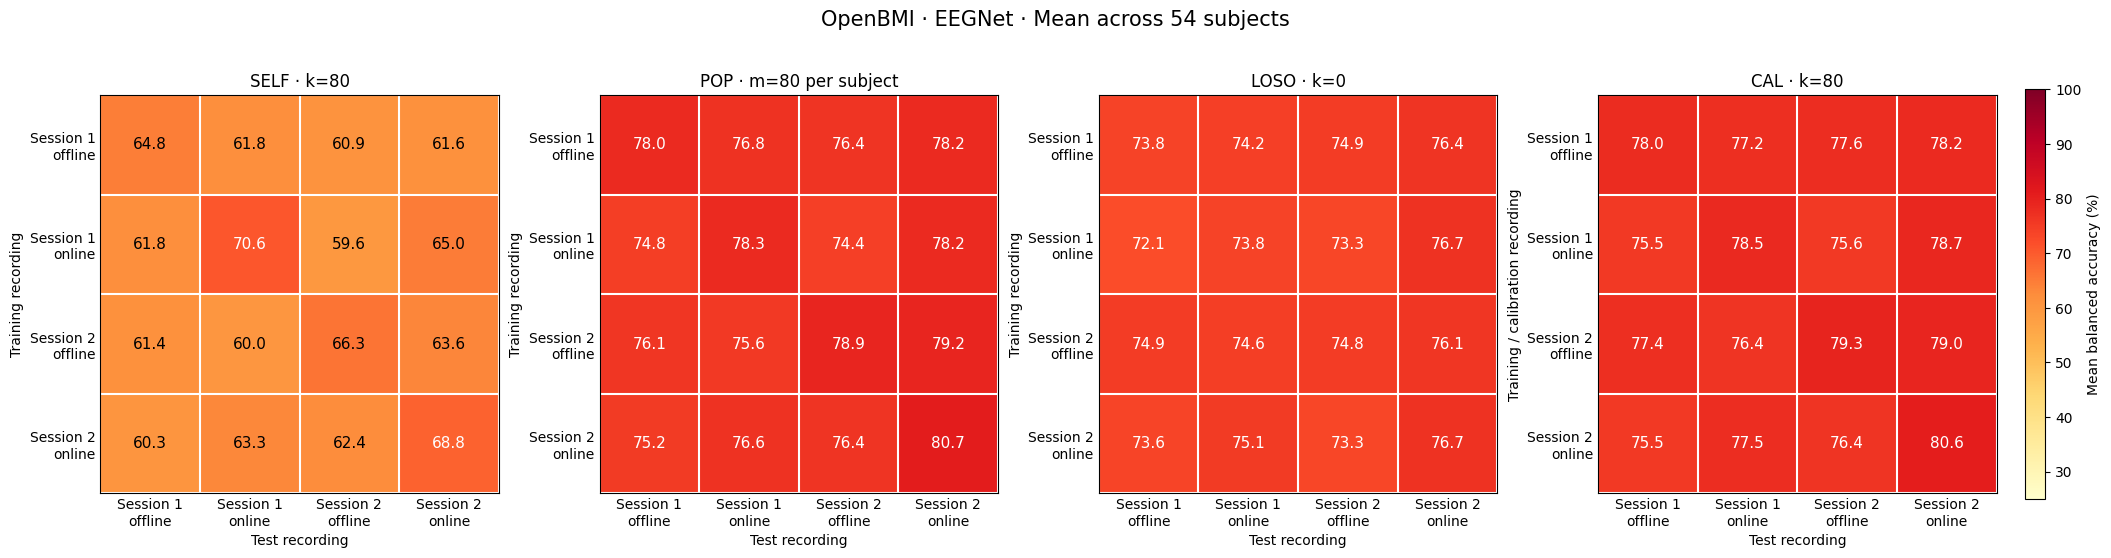

In [19]:
vmin, vmax = 25, 100

cmap = plt.get_cmap("YlOrRd").copy()
cmap.set_bad("#EEEEEE")
norm = plt.Normalize(vmin=vmin, vmax=vmax)

titles = {
    "SELF": f"SELF · k={k}",
    "POP": f"POP · m={k} per subject",
    "LOSO": "LOSO · k=0",
    "CAL": f"CAL · k={k}",
}

fig, axes = plt.subplots(
    1, 4,
    figsize=(21, 5.5),
    layout="constrained",
)

for ax, protocol in zip(axes, ("SELF", "POP", "LOSO", "CAL")):
    matrix = matrices[protocol]

    im = ax.imshow(
        np.ma.masked_invalid(matrix),
        cmap=cmap,
        norm=norm,
        aspect="equal",
    )

    ax.set_title(titles[protocol], fontsize=12)
    ax.set_xlabel("Test recording")
    ax.set_ylabel(
        "Training / calibration recording"
        if protocol == "CAL"
        else "Training recording"
    )

    ax.set_xticks(range(4), labels=labels)
    ax.set_yticks(range(4), labels=labels)
    ax.set_xticks(np.arange(-0.5, 4, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, 4, 1), minor=True)
    ax.grid(which="minor", color="white", linewidth=1.5)
    ax.tick_params(which="both", length=0)

    for row in range(4):
        for col in range(4):
            value = matrix[row, col]

            if np.isnan(value):
                text, color = "—", "gray"
            else:
                text = f"{value:.1f}"
                r, g, b, _ = cmap(norm(value))
                brightness = 0.299 * r + 0.587 * g + 0.114 * b
                color = "black" if brightness > 0.55 else "white"

            ax.text(
                col, row, text,
                ha="center", va="center",
                fontsize=11, color=color,
            )

fig.colorbar(
    im,
    ax=axes.tolist(),
    label="Mean balanced accuracy (%)",
    shrink=0.8,
    pad=0.015,
)

fig.suptitle(
    "OpenBMI · EEGNet · Mean across 54 subjects",
    fontsize=15,
)

plt.show()

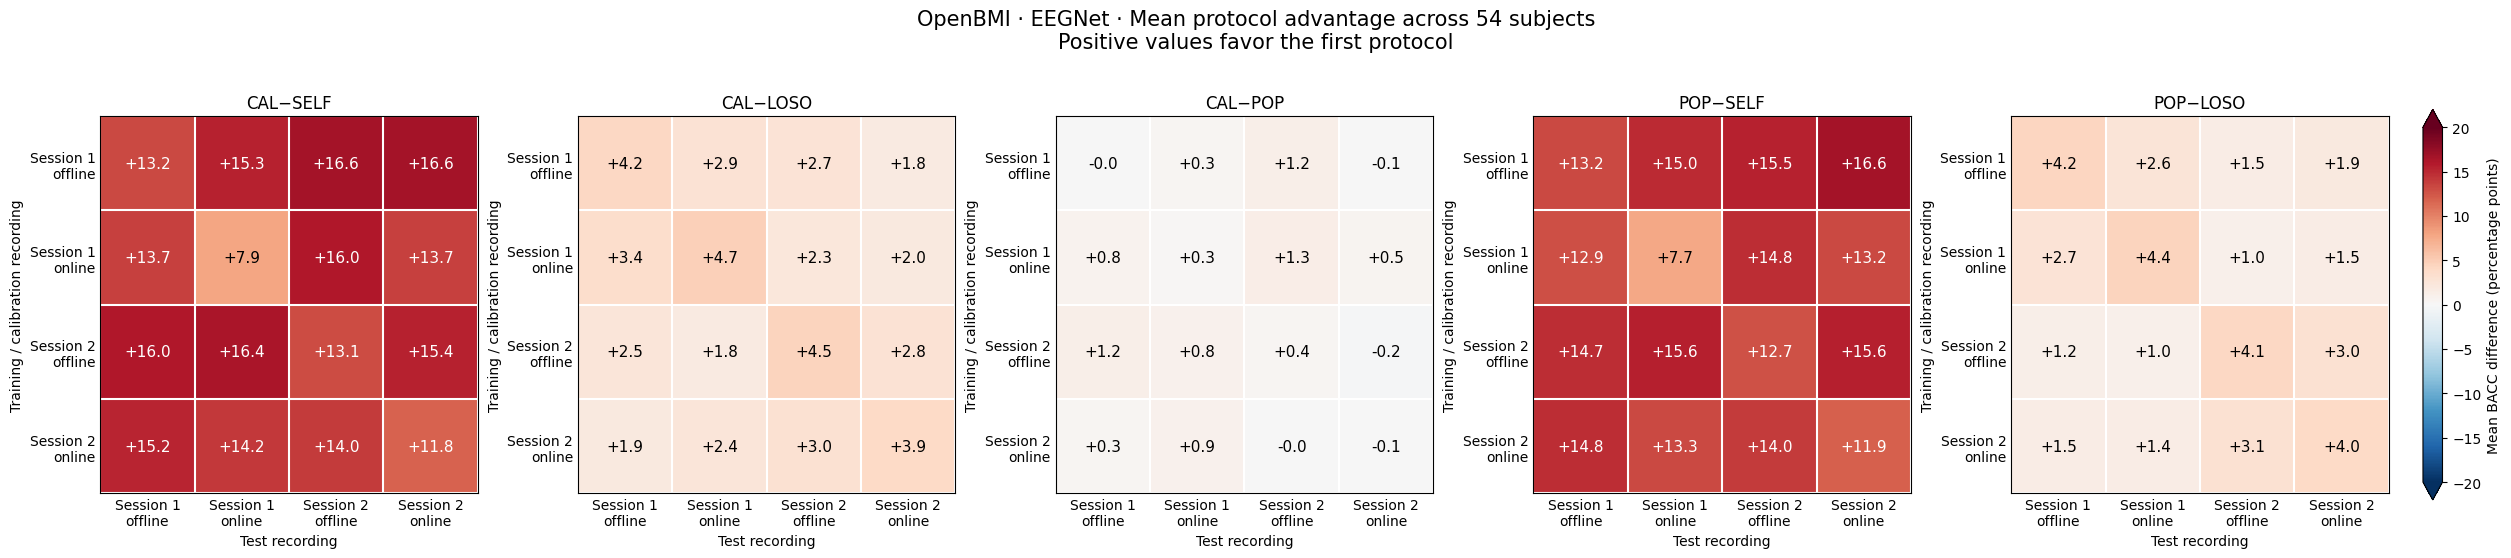

In [20]:
comparisons = [
    ("CAL", "SELF"),
    ("CAL", "LOSO"),
    ("CAL", "POP"),
    ("POP", "SELF"),
    ("POP", "LOSO"),
]

# matrices 已经是百分数，直接相减得到百分点
difference_matrices = {
    f"{a}−{b}": matrices[a] - matrices[b]
    for a, b in comparisons
}

# 所有子图共用对称色阶，可自行修改
color_limit = 20

cmap = plt.get_cmap("RdBu_r").copy()
cmap.set_bad("#EEEEEE")
norm = plt.Normalize(
    vmin=-color_limit,
    vmax=color_limit,
)

fig, axes = plt.subplots(
    1, 5,
    figsize=(25, 5.5),
    layout="constrained",
)

for ax, (title, matrix) in zip(
    axes, difference_matrices.items()
):
    im = ax.imshow(
        np.ma.masked_invalid(matrix),
        cmap=cmap,
        norm=norm,
        aspect="equal",
    )

    ax.set_title(title, fontsize=12)
    ax.set_xlabel("Test recording")
    ax.set_ylabel("Training / calibration recording")

    ax.set_xticks(range(4), labels=labels)
    ax.set_yticks(range(4), labels=labels)
    ax.set_xticks(np.arange(-0.5, 4, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, 4, 1), minor=True)
    ax.grid(which="minor", color="white", linewidth=1.5)
    ax.tick_params(which="both", length=0)

    for row in range(4):
        for col in range(4):
            value = matrix[row, col]

            if np.isnan(value):
                text, color = "—", "gray"
            else:
                text = f"{value:+.1f}"
                r, g, b, _ = cmap(norm(value))
                brightness = 0.299 * r + 0.587 * g + 0.114 * b
                color = "black" if brightness > 0.55 else "white"

            ax.text(
                col, row, text,
                ha="center", va="center",
                fontsize=11, color=color,
            )

fig.colorbar(
    im,
    ax=axes.tolist(),
    label="Mean BACC difference (percentage points)",
    shrink=0.8,
    pad=0.015,
    extend="both",
)

fig.suptitle(
    "OpenBMI · EEGNet · Mean protocol advantage across 54 subjects\n"
    "Positive values favor the first protocol",
    fontsize=15,
)

plt.show()

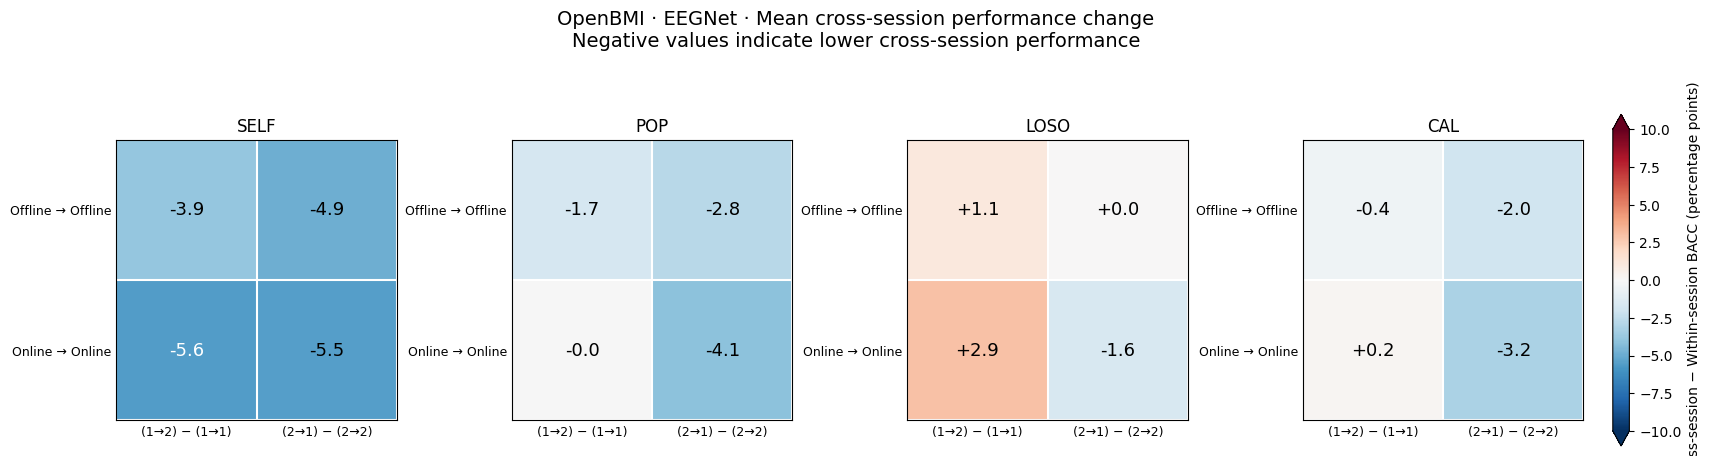

In [26]:
# matrices 的行列顺序：
# Session 1 offline、Session 1 online、
# Session 2 offline、Session 2 online

protocol_order = ["SELF", "POP", "LOSO", "CAL"]

cross_session_matrices = {}

for protocol in protocol_order:
    m = matrices[protocol]

    cross_session_matrices[protocol] = np.array([
        [
            m[0, 2] - m[0, 0],  # Offline: (1→2) − (1→1)
            m[2, 0] - m[2, 2],  # Offline: (2→1) − (2→2)
        ],
        [
            m[1, 3] - m[1, 1],  # Online: (1→2) − (1→1)
            m[3, 1] - m[3, 3],  # Online: (2→1) − (2→2)
        ],
    ])

# 所有子图共用对称色阶
color_limit = 10

cmap = plt.get_cmap("RdBu_r").copy()
cmap.set_bad("#EEEEEE")
norm = plt.Normalize(vmin=-color_limit, vmax=color_limit)

fig, axes = plt.subplots(
    1, 4,
    figsize=(17, 5),
    layout="constrained",
)

for ax, protocol in zip(axes, protocol_order):
    matrix = cross_session_matrices[protocol]

    im = ax.imshow(
        np.ma.masked_invalid(matrix),
        cmap=cmap,
        norm=norm,
        aspect="equal",
    )

    ax.set_title(protocol, fontsize=12)
    ax.set_xticks(
        [0, 1],
        labels=[
            "(1→2) − (1→1)",
            "(2→1) − (2→2)",
        ],
        fontsize=9,
    )
    ax.set_yticks(
        [0, 1],
        labels=["Offline → Offline", "Online → Online"],
        fontsize=9,
    )

    ax.set_xticks(np.arange(-0.5, 2, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, 2, 1), minor=True)
    ax.grid(which="minor", color="white", linewidth=1.5)
    ax.tick_params(which="both", length=0)

    for row in range(2):
        for col in range(2):
            value = matrix[row, col]

            if np.isnan(value):
                text, color = "—", "gray"
            else:
                text = f"{value:+.1f}"
                r, g, b, _ = cmap(norm(value))
                brightness = 0.299 * r + 0.587 * g + 0.114 * b
                color = "black" if brightness > 0.55 else "white"

            ax.text(
                col, row, text,
                ha="center", va="center",
                fontsize=13, color=color,
            )

fig.colorbar(
    im,
    ax=axes.tolist(),
    label="Cross-session − Within-session BACC (percentage points)",
    shrink=0.75,
    pad=0.02,
    extend="both",
)

fig.suptitle(
    "OpenBMI · EEGNet · Mean cross-session performance change\n"
    "Negative values indicate lower cross-session performance",
    fontsize=14,
)

plt.show()

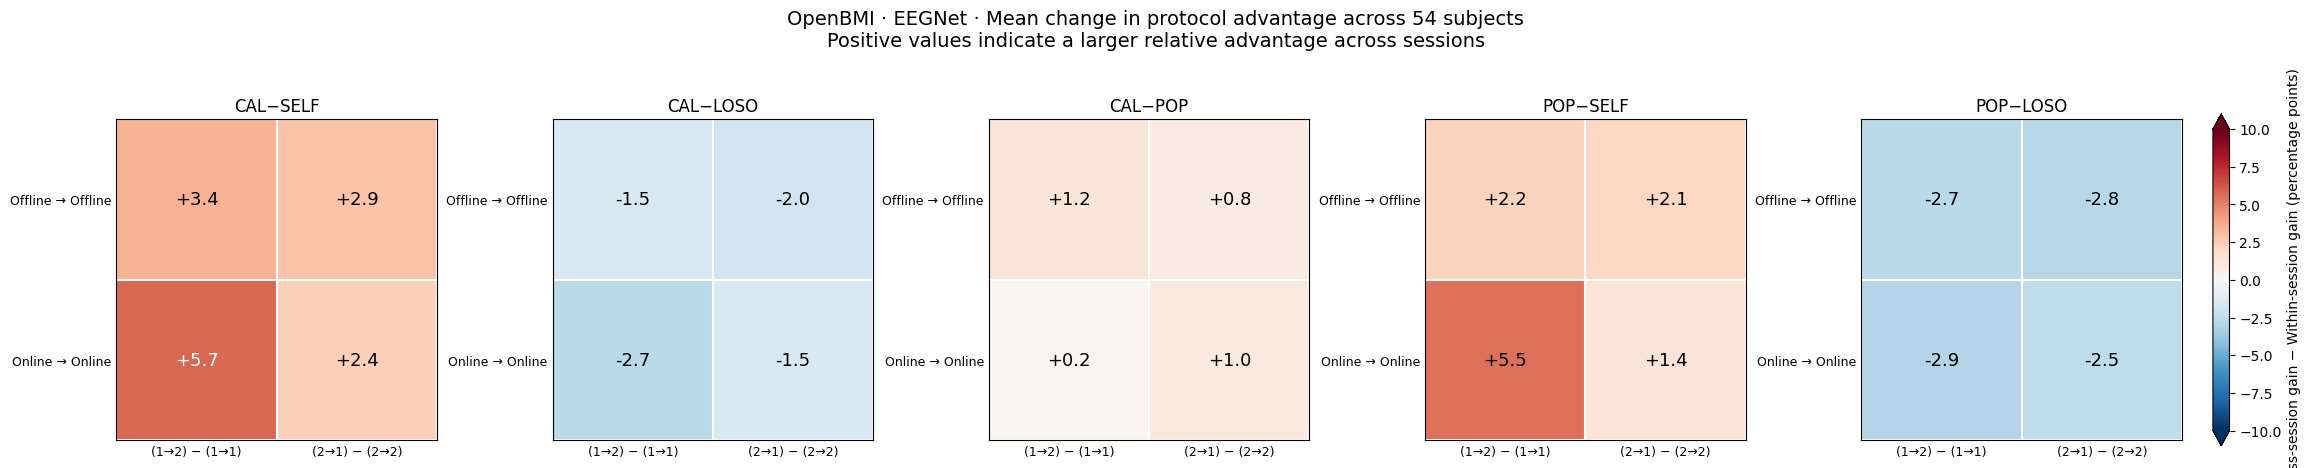

In [31]:
comparisons = [
    ("CAL", "SELF"),
    ("CAL", "LOSO"),
    ("CAL", "POP"),
    ("POP", "SELF"),
    ("POP", "LOSO"),
]

# matrices 行列顺序：
# Session 1 offline、Session 1 online、
# Session 2 offline、Session 2 online

gain_change_matrices = {}

for a, b in comparisons:
    gain = matrices[a] - matrices[b]

    gain_change_matrices[f"{a}−{b}"] = np.array([
        [
            gain[0, 2] - gain[0, 0],  # Offline: gain(1→2) − gain(1→1)
            gain[2, 0] - gain[2, 2],  # Offline: gain(2→1) − gain(2→2)
        ],
        [
            gain[1, 3] - gain[1, 1],  # Online: gain(1→2) − gain(1→1)
            gain[3, 1] - gain[3, 3],  # Online: gain(2→1) − gain(2→2)
        ],
    ])

color_limit = 10
cmap = plt.get_cmap("RdBu_r").copy()
cmap.set_bad("#EEEEEE")
norm = plt.Normalize(vmin=-color_limit, vmax=color_limit)

fig, axes = plt.subplots(
    1, 5,
    figsize=(23, 5),
    layout="constrained",
)

for ax, (title, matrix) in zip(
    axes, gain_change_matrices.items()
):
    im = ax.imshow(
        np.ma.masked_invalid(matrix),
        cmap=cmap,
        norm=norm,
        aspect="equal",
    )

    ax.set_title(title, fontsize=12)
    ax.set_xticks(
        [0, 1],
        labels=[
            "(1→2) − (1→1)",
            "(2→1) − (2→2)",
        ],
        fontsize=9,
    )
    ax.set_yticks(
        [0, 1],
        labels=["Offline → Offline", "Online → Online"],
        fontsize=9,
    )

    ax.set_xticks(np.arange(-0.5, 2, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, 2, 1), minor=True)
    ax.grid(which="minor", color="white", linewidth=1.5)
    ax.tick_params(which="both", length=0)

    for row in range(2):
        for col in range(2):
            value = matrix[row, col]

            if np.isnan(value):
                text, color = "—", "gray"
            else:
                text = f"{value:+.1f}"
                r, g, b, _ = cmap(norm(value))
                brightness = 0.299 * r + 0.587 * g + 0.114 * b
                color = "black" if brightness > 0.55 else "white"

            ax.text(
                col, row, text,
                ha="center", va="center",
                fontsize=13, color=color,
            )

fig.colorbar(
    im,
    ax=axes.tolist(),
    label="Cross-session gain − Within-session gain (percentage points)",
    shrink=0.75,
    pad=0.015,
    extend="both",
)

fig.suptitle(
    "OpenBMI · EEGNet · Mean change in protocol advantage across 54 subjects\n"
    "Positive values indicate a larger relative advantage across sessions",
    fontsize=14,
)

plt.show()

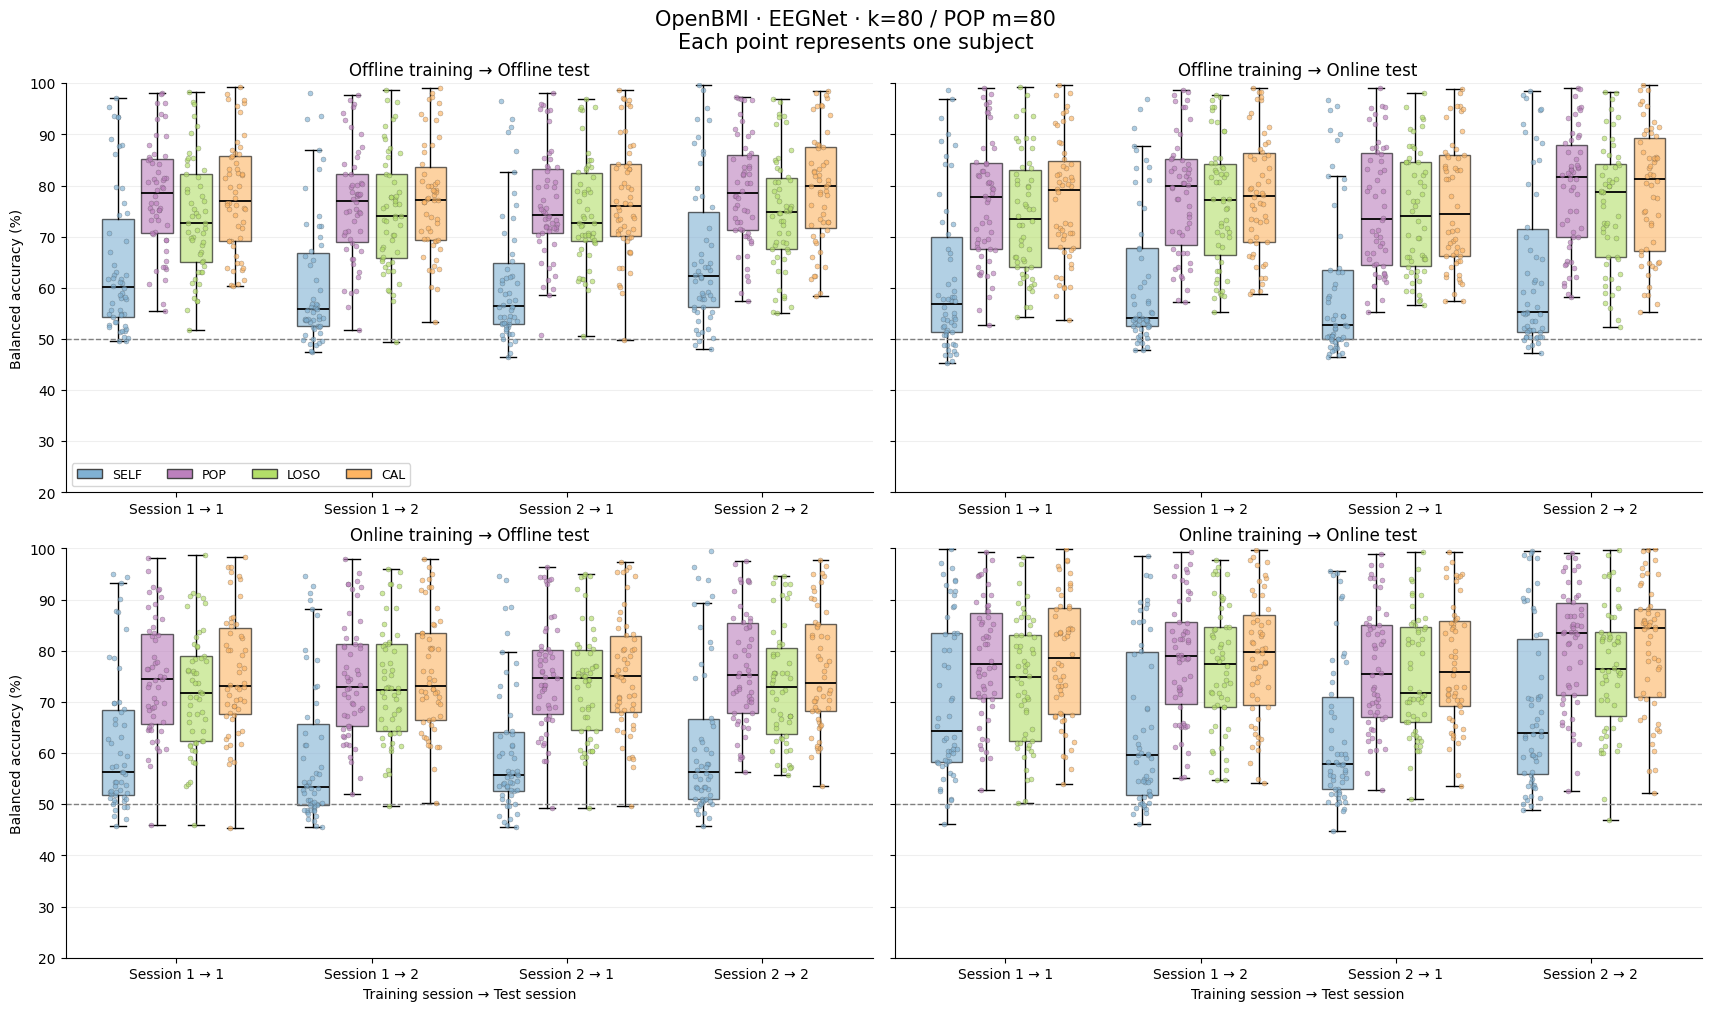

In [15]:
from matplotlib.patches import Patch

protocols = ["SELF", "POP", "LOSO", "CAL"]
session_pairs = [("1", "1"), ("1", "2"), ("2", "1"), ("2", "2")]

colors = {
    "SELF": "#80B1D3",
    "LOSO": "#B3DE69",
    "CAL": "#FDB462",
    "POP": "#BC80BD",
}

centers = np.arange(4) * 3
offsets = [-0.9, -0.3, 0.3, 0.9]
rng = np.random.default_rng(0)

fig, axes = plt.subplots(
    2, 2,
    figsize=(17, 10),
    sharex=True,
    sharey=True,
    layout="constrained",
)

for row, train_phase in enumerate(["offline", "online"]):
    for col, test_phase in enumerate(["offline", "online"]):
        ax = axes[row, col]

        for center, (train_ses, test_ses) in zip(
            centers, session_pairs
        ):
            for protocol, offset in zip(protocols, offsets):
                selected = subject_scores[
                    (subject_scores["protocol"] == protocol)
                    & (subject_scores["train_sess"] == train_ses)
                    & (subject_scores["train_phases"] == train_phase)
                    & (subject_scores["test_ses"] == test_ses)
                    & (subject_scores["test_phase"] == test_phase)
                ]

                if selected.empty:
                    continue

                if set(selected["subject"]) != set(range(1, 55)):
                    raise ValueError(
                        f"被试不完整：{protocol}, "
                        f"{train_ses}/{train_phase} → "
                        f"{test_ses}/{test_phase}"
                    )

                values = selected["bacc"].to_numpy() * 100
                position = center + offset
                color = colors[protocol]

                box = ax.boxplot(
                    [values],
                    positions=[position],
                    widths=0.48,
                    patch_artist=True,
                    showfliers=False,
                    manage_ticks=False,
                    medianprops={
                        "color": "black",
                        "linewidth": 1.3,
                    },
                )
                box["boxes"][0].set_facecolor(color)
                box["boxes"][0].set_alpha(0.6)

                ax.scatter(
                    position + rng.uniform(-0.15, 0.15, len(values)),
                    values,
                    s=13,
                    color=color,
                    edgecolors="#444444",
                    linewidths=0.25,
                    alpha=0.65,
                    zorder=3,
                )

        ax.axhline(50, color="gray", linestyle="--", linewidth=1)
        ax.set_title(
            f"{train_phase.capitalize()} training → "
            f"{test_phase.capitalize()} test"
        )
        ax.set_xticks(
            centers,
            labels=[
                f"Session {a} → {b}" for a, b in session_pairs
            ],
        )
        ax.tick_params(axis="x", labelbottom=True)
        ax.set_ylim(20, 100)
        ax.set_yticks(np.arange(20, 101, 10))
        ax.set_axisbelow(True)
        ax.grid(axis="y", alpha=0.2)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

        if col == 0:
            ax.set_ylabel("Balanced accuracy (%)")

        if row == 1:
            ax.set_xlabel("Training session → Test session")

axes[0, 0].legend(
    handles=[
        Patch(
            facecolor=colors[p],
            edgecolor="#444444",
            label=p,
        )
        for p in protocols
    ],
    ncol=4,
    loc="lower left",
    fontsize=9,
)

fig.suptitle(
    f"OpenBMI · EEGNet · k={k} / POP m={k}\n"
    "Each point represents one subject",
    fontsize=15,
)

plt.show()

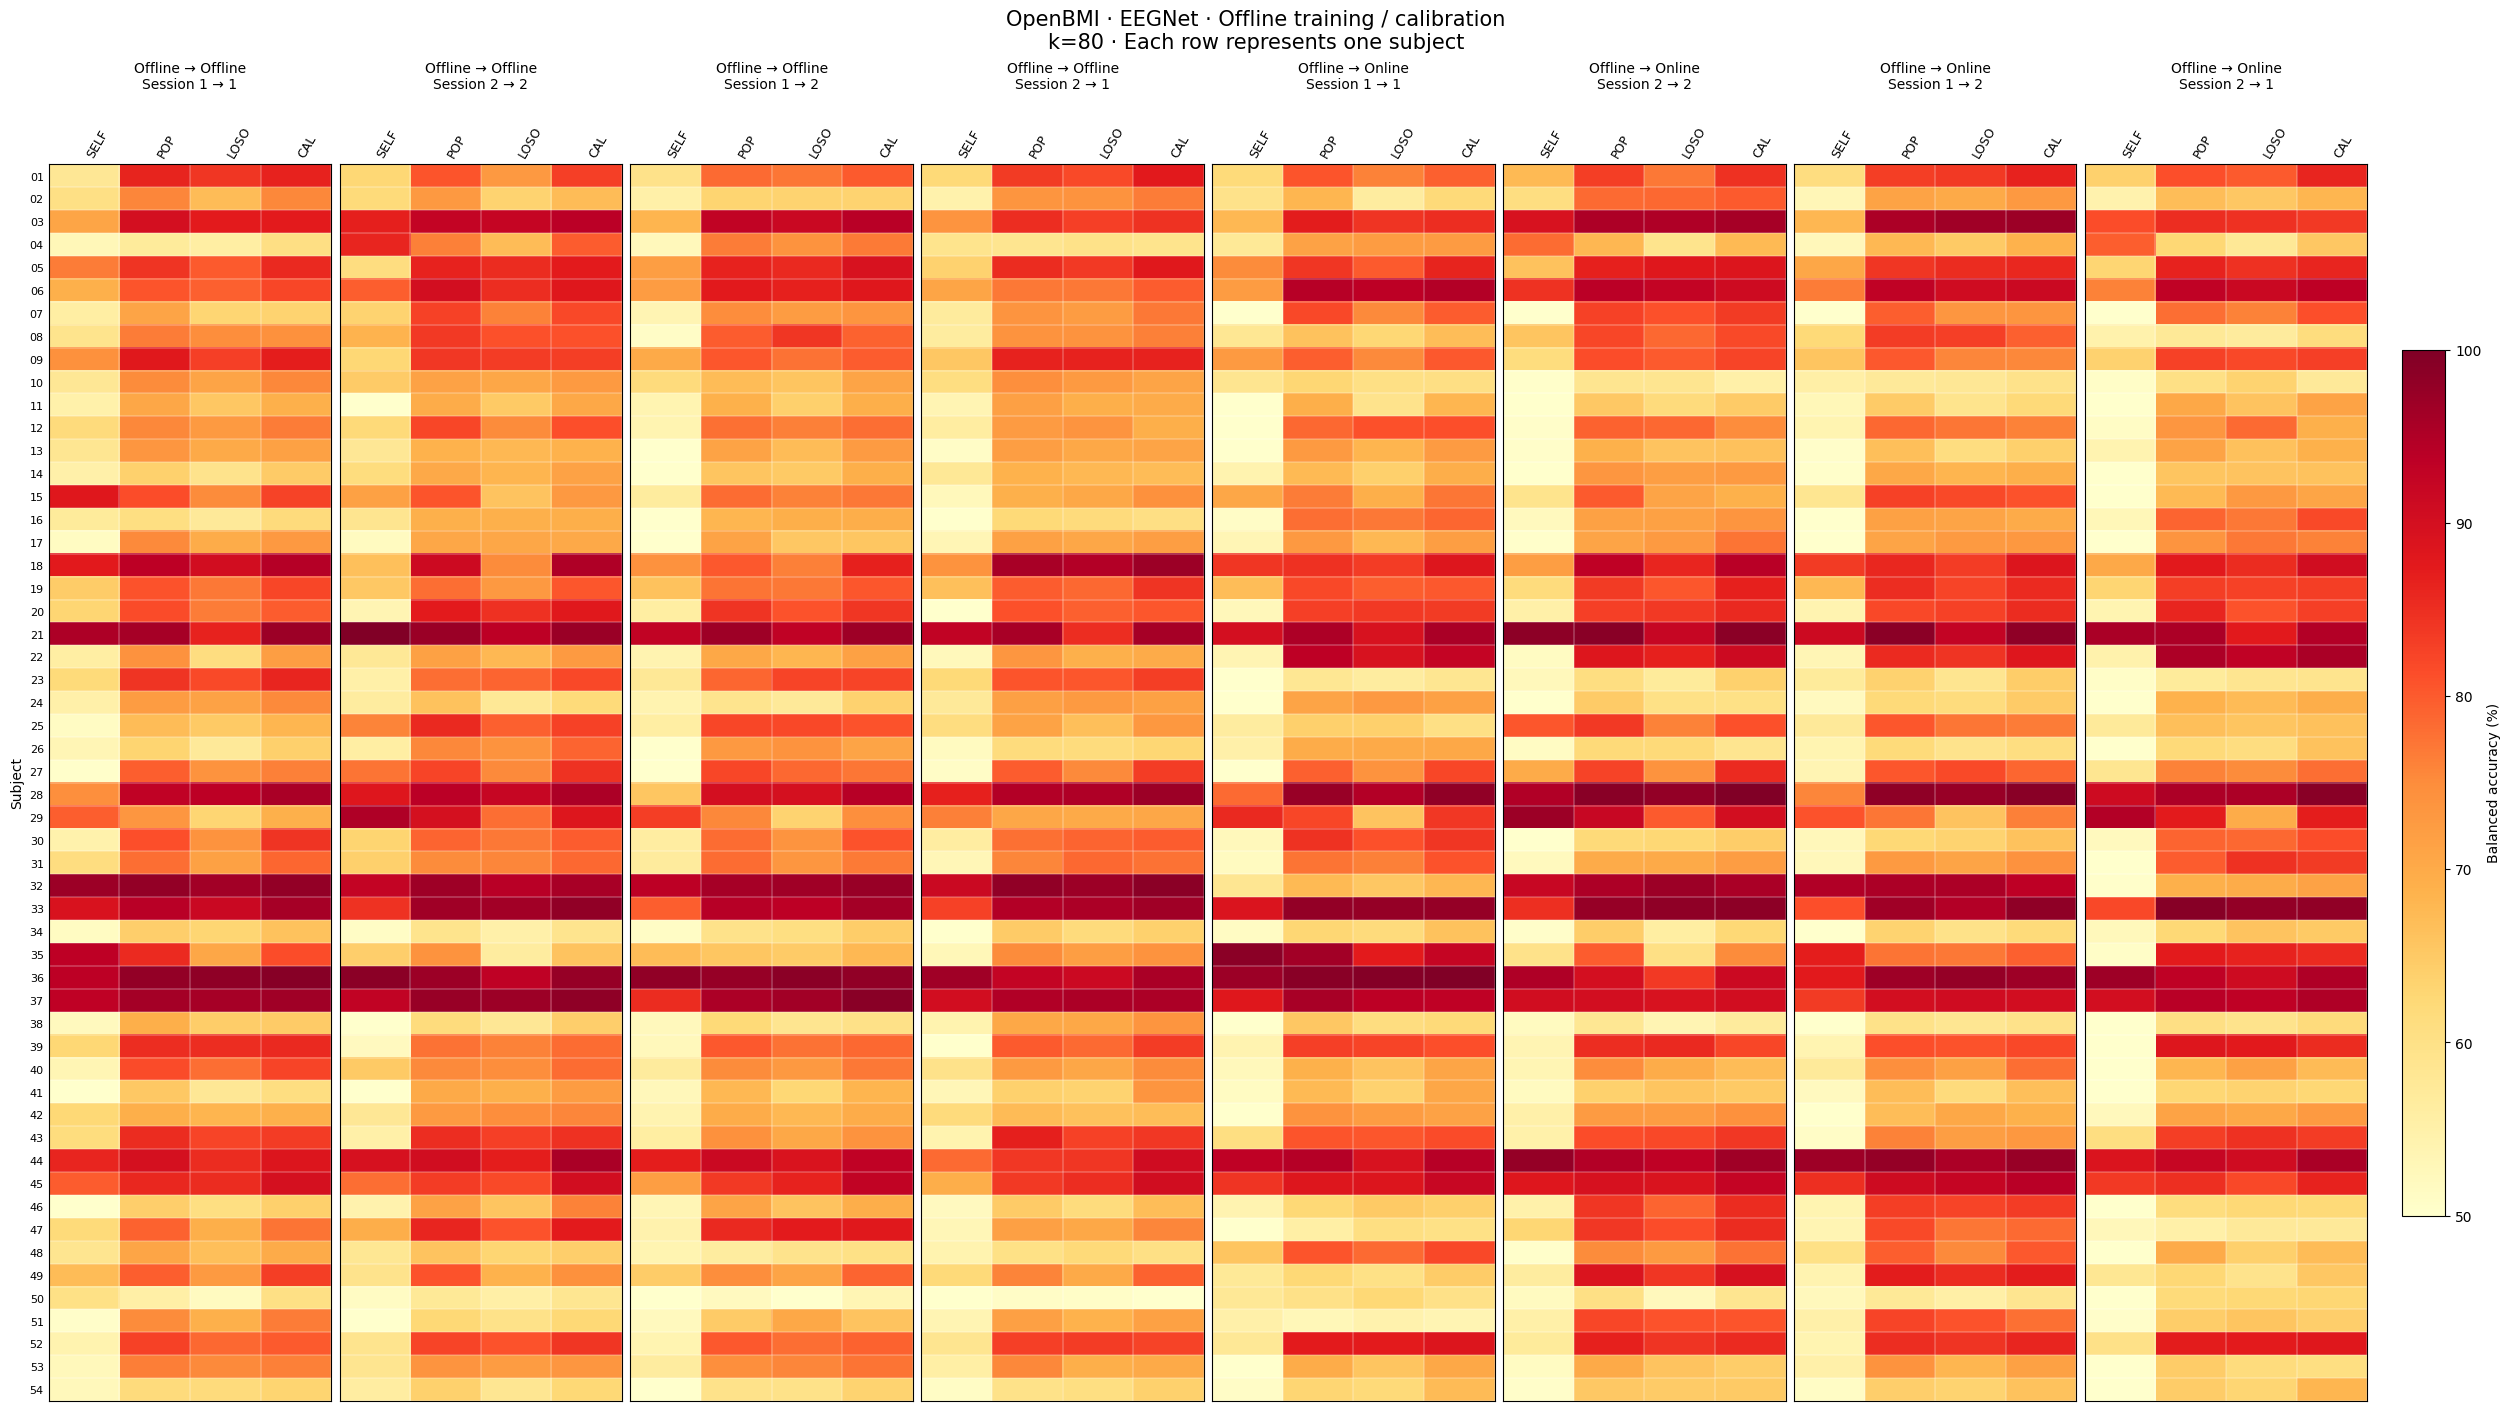

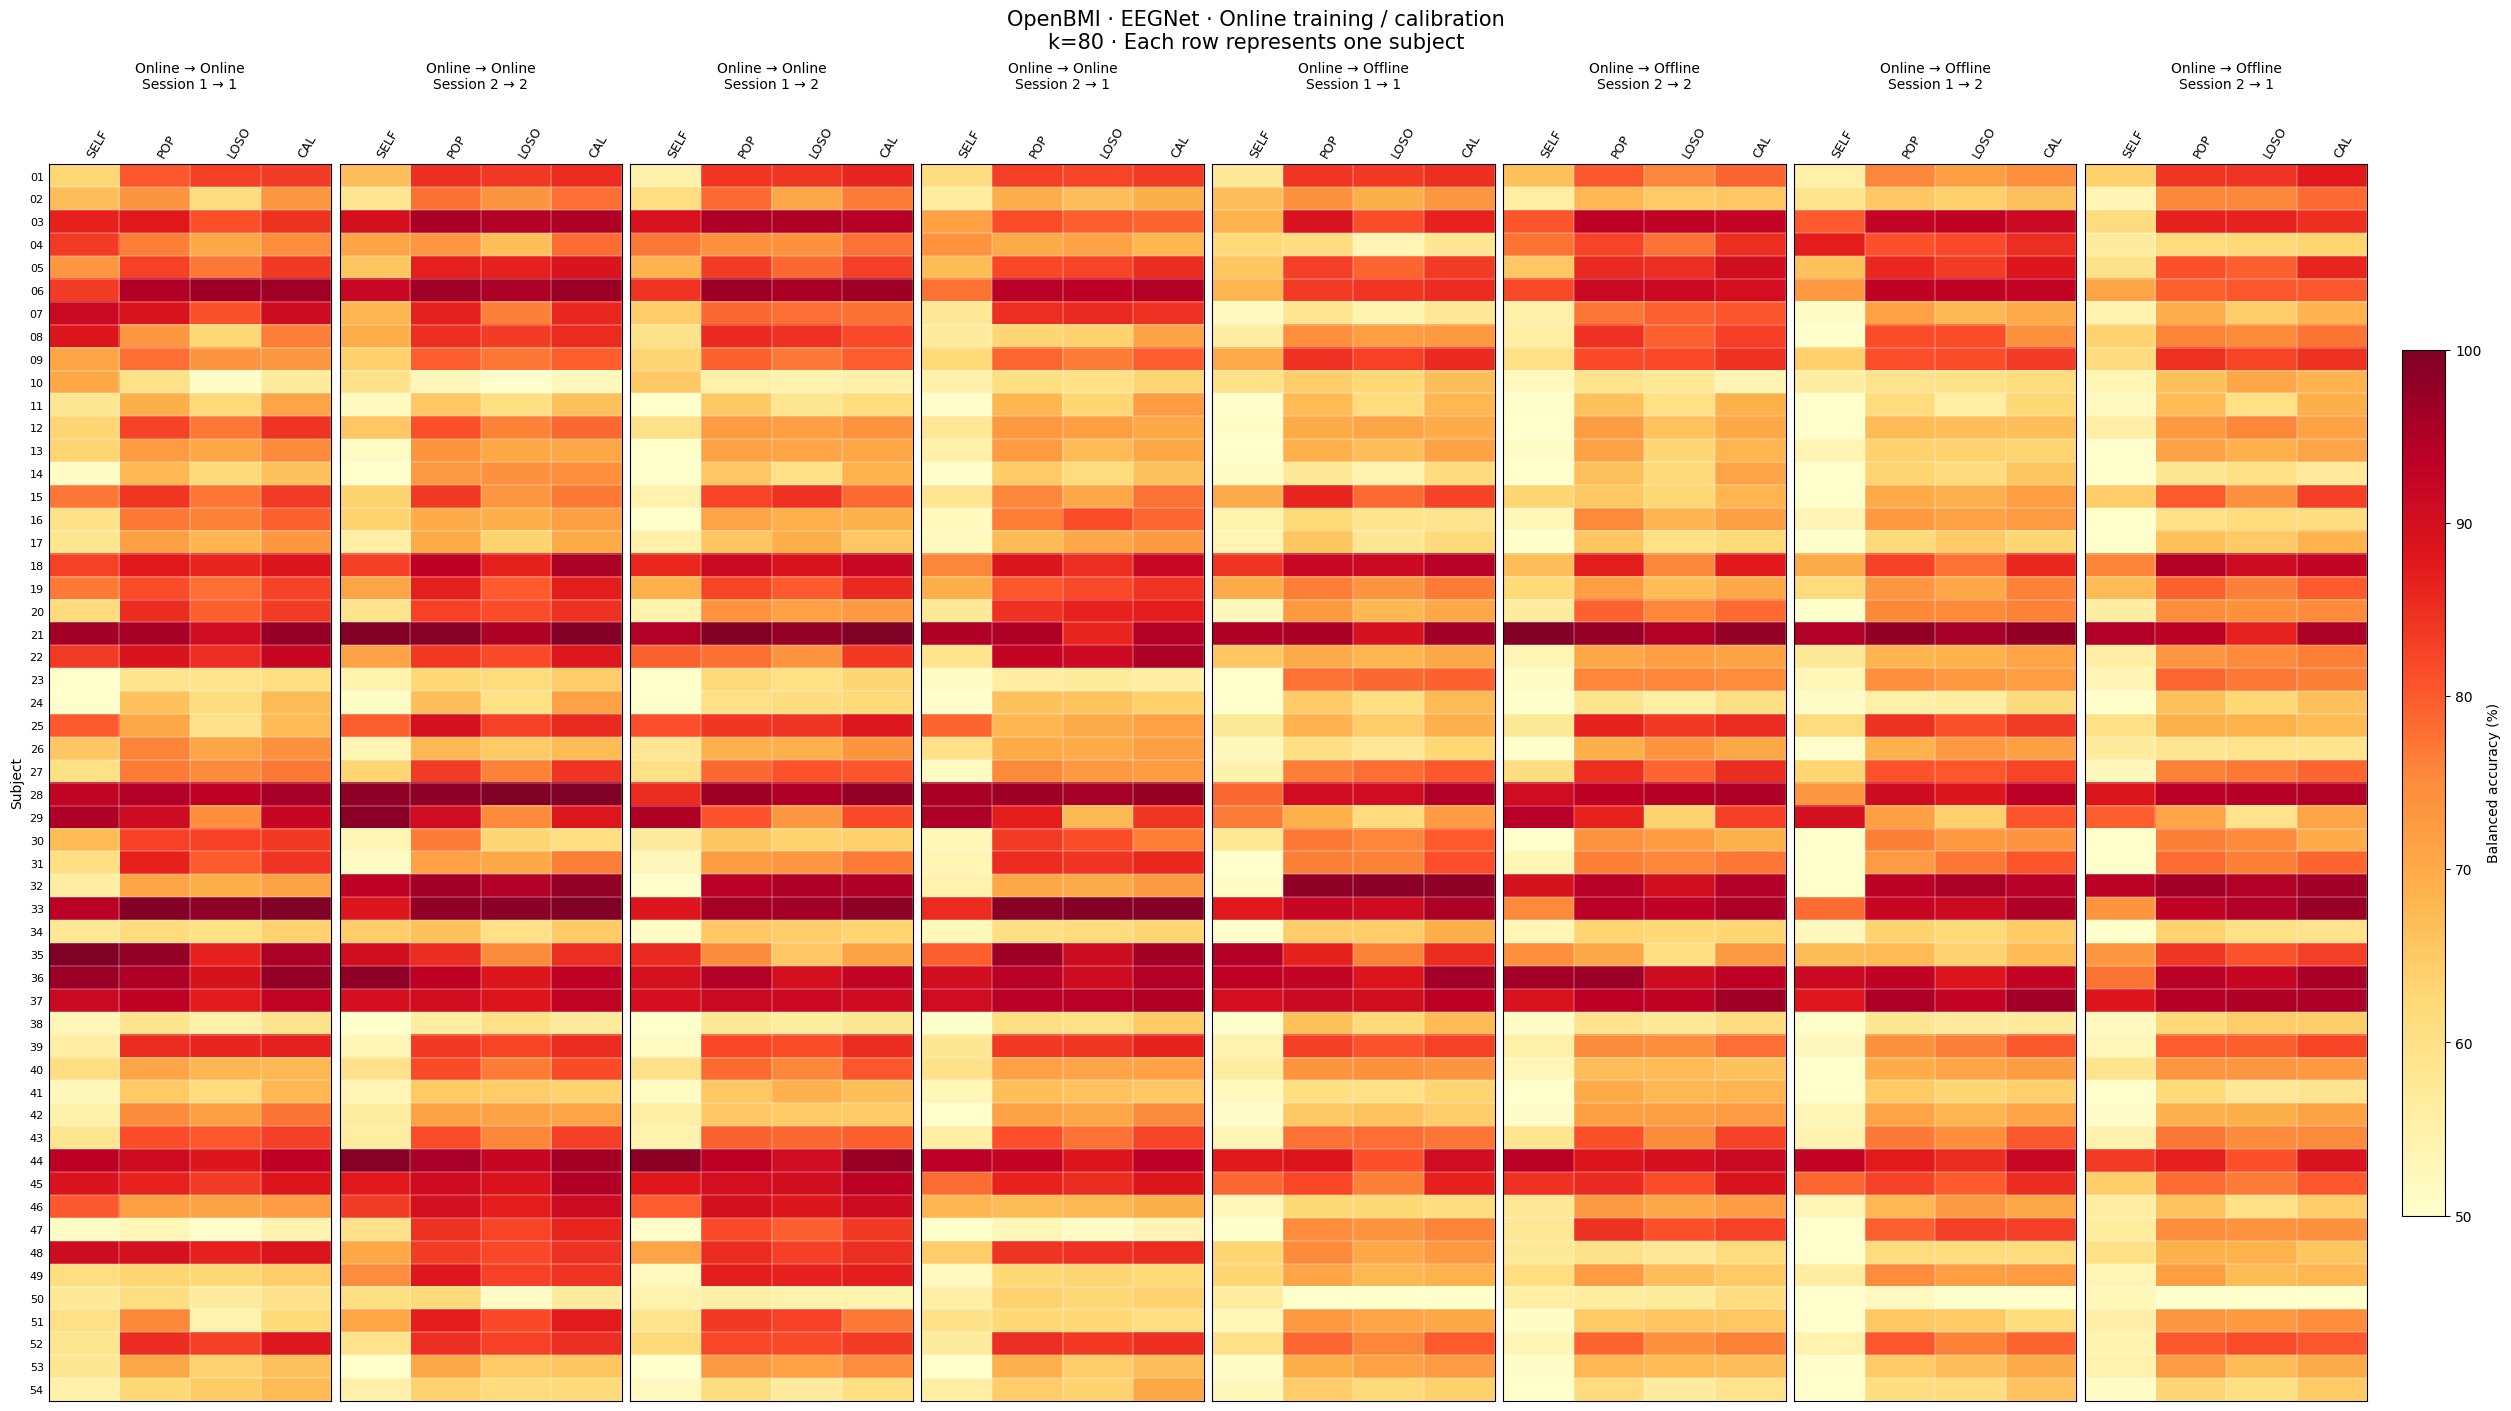

In [16]:
# ---------- 个体准确率 heatmap ----------
protocol_order = ["SELF", "POP", "LOSO", "CAL"]
session_pairs = [("1", "1"), ("2", "2"), ("1", "2"), ("2", "1")]
subjects = list(range(1, 55))

accuracy_scores = subject_scores.copy()

for col in ("train_sess", "test_ses"):
    accuracy_scores[col] = (
        accuracy_scores[col].astype(str)
        .str.replace(r"\.0$", "", regex=True)
    )

# 所有面板共用色阶，可自行修改
vmin, vmax = 50, 100
cmap = plt.get_cmap("YlOrRd").copy()
cmap.set_bad("#EEEEEE")
norm = plt.Normalize(vmin=vmin, vmax=vmax)

for train_phase in ("offline", "online"):
    other_phase = "online" if train_phase == "offline" else "offline"

    fig, axes = plt.subplots(
        1, 8,
        figsize=(25, 14),
        sharey=True,
        layout="constrained",
    )

    panel_id = 0

    for test_phase in (train_phase, other_phase):
        for train_ses, test_ses in session_pairs:
            ax = axes[panel_id]

            selected = accuracy_scores[
                (accuracy_scores["train_sess"] == train_ses)
                & (accuracy_scores["train_phases"] == train_phase)
                & (accuracy_scores["test_ses"] == test_ses)
                & (accuracy_scores["test_phase"] == test_phase)
            ]

            matrix = (
                selected.pivot(
                    index="subject",
                    columns="protocol",
                    values="bacc",
                )
                .reindex(index=subjects, columns=protocol_order)
                * 100
            )

            if matrix.isna().any().any():
                missing = matrix.index[
                    matrix.isna().any(axis=1)
                ].tolist()
                raise ValueError(
                    f"{train_phase} → {test_phase}, "
                    f"Session {train_ses} → {test_ses}，"
                    f"存在缺失分数，被试：{missing}"
                )

            im = ax.imshow(
                matrix.to_numpy(),
                cmap=cmap,
                norm=norm,
                aspect="auto",
                interpolation="nearest",
            )

            ax.set_title(
                f"{train_phase.capitalize()} → "
                f"{test_phase.capitalize()}\n"
                f"Session {train_ses} → {test_ses}",
                fontsize=10,
                pad=55,
            )

            ax.set_xticks(
                range(len(protocol_order)),
                labels=protocol_order,
                rotation=60,
                ha="left",
                fontsize=9,
            )
            ax.tick_params(
                axis="x",
                top=True,
                labeltop=True,
                bottom=False,
                labelbottom=False,
            )

            ax.set_yticks(
                range(len(subjects)),
                labels=[f"{s:02d}" for s in subjects],
            )
            ax.tick_params(
                axis="y",
                labelleft=(panel_id == 0),
                labelsize=8,
            )
            ax.tick_params(which="both", length=0)

            ax.set_xticks(
                np.arange(-0.5, len(protocol_order), 1),
                minor=True,
            )
            ax.set_yticks(
                np.arange(-0.5, len(subjects), 1),
                minor=True,
            )
            ax.grid(
                which="minor",
                color="white",
                linewidth=0.3,
            )

            if panel_id == 0:
                ax.set_ylabel("Subject")

            panel_id += 1

    fig.colorbar(
        im,
        ax=axes.tolist(),
        label="Balanced accuracy (%)",
        shrink=0.7,
        pad=0.015,
    )

    fig.suptitle(
        f"OpenBMI · EEGNet · "
        f"{train_phase.capitalize()} training / calibration\n"
        f"k={k} · Each row represents one subject",
        fontsize=15,
    )

    plt.show()

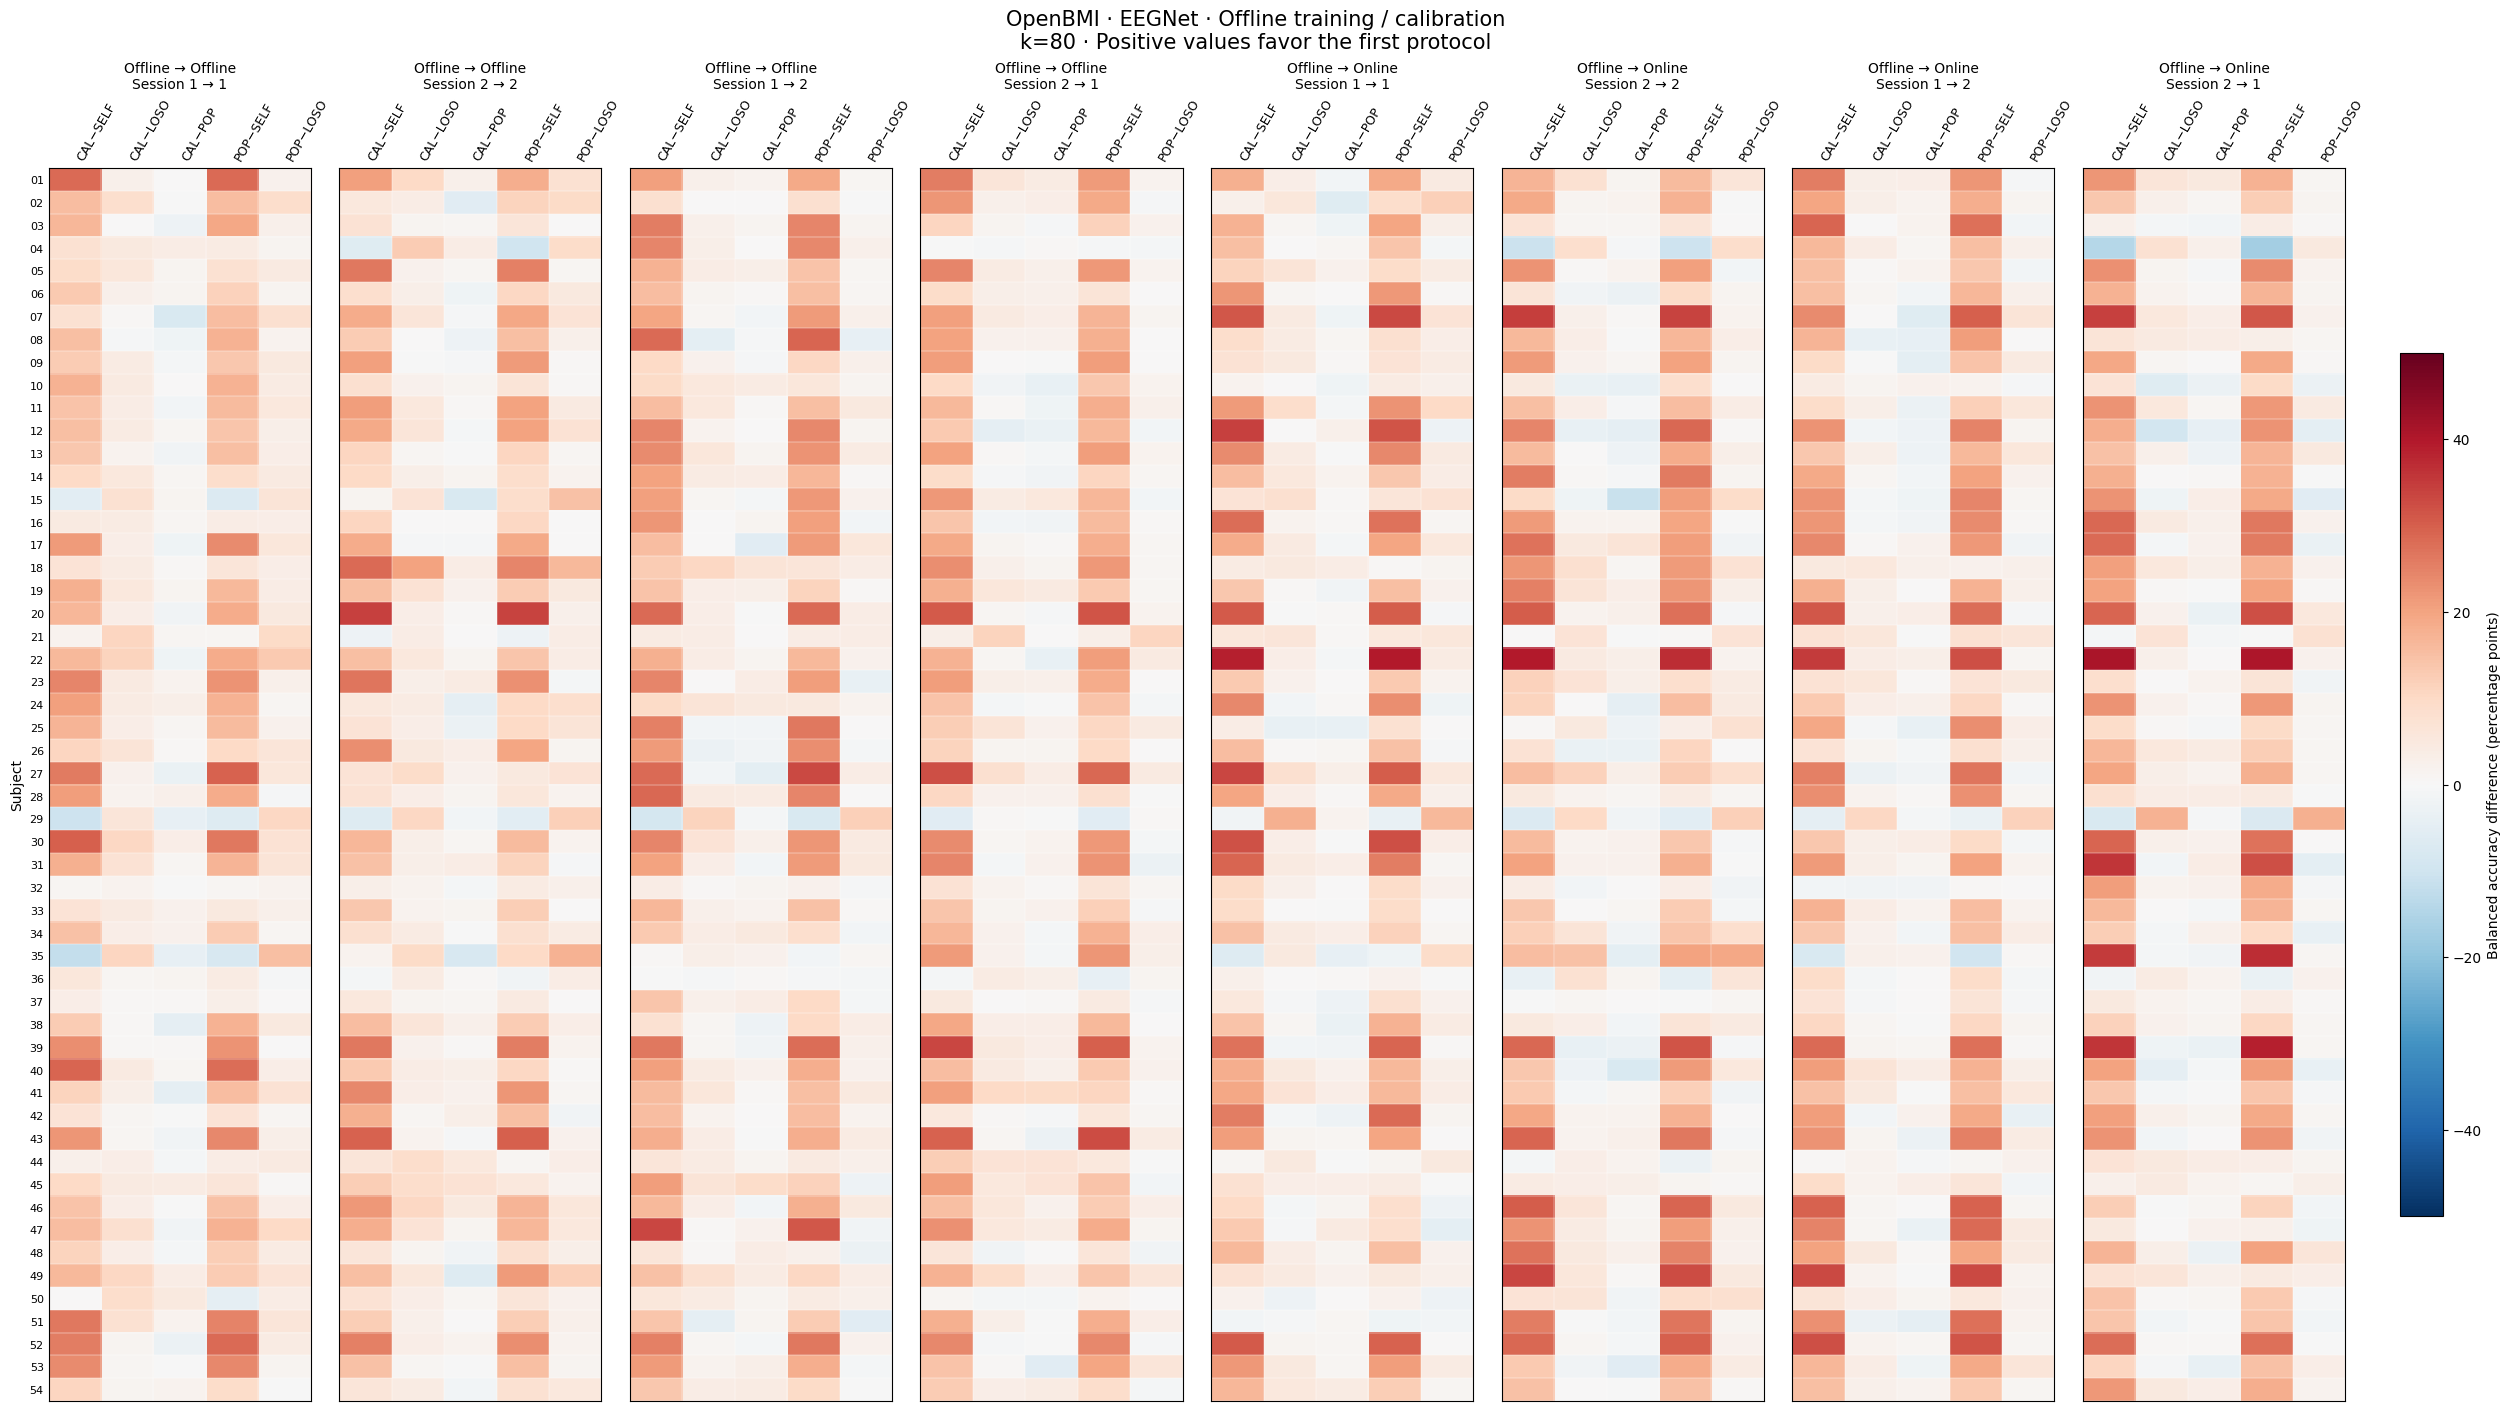

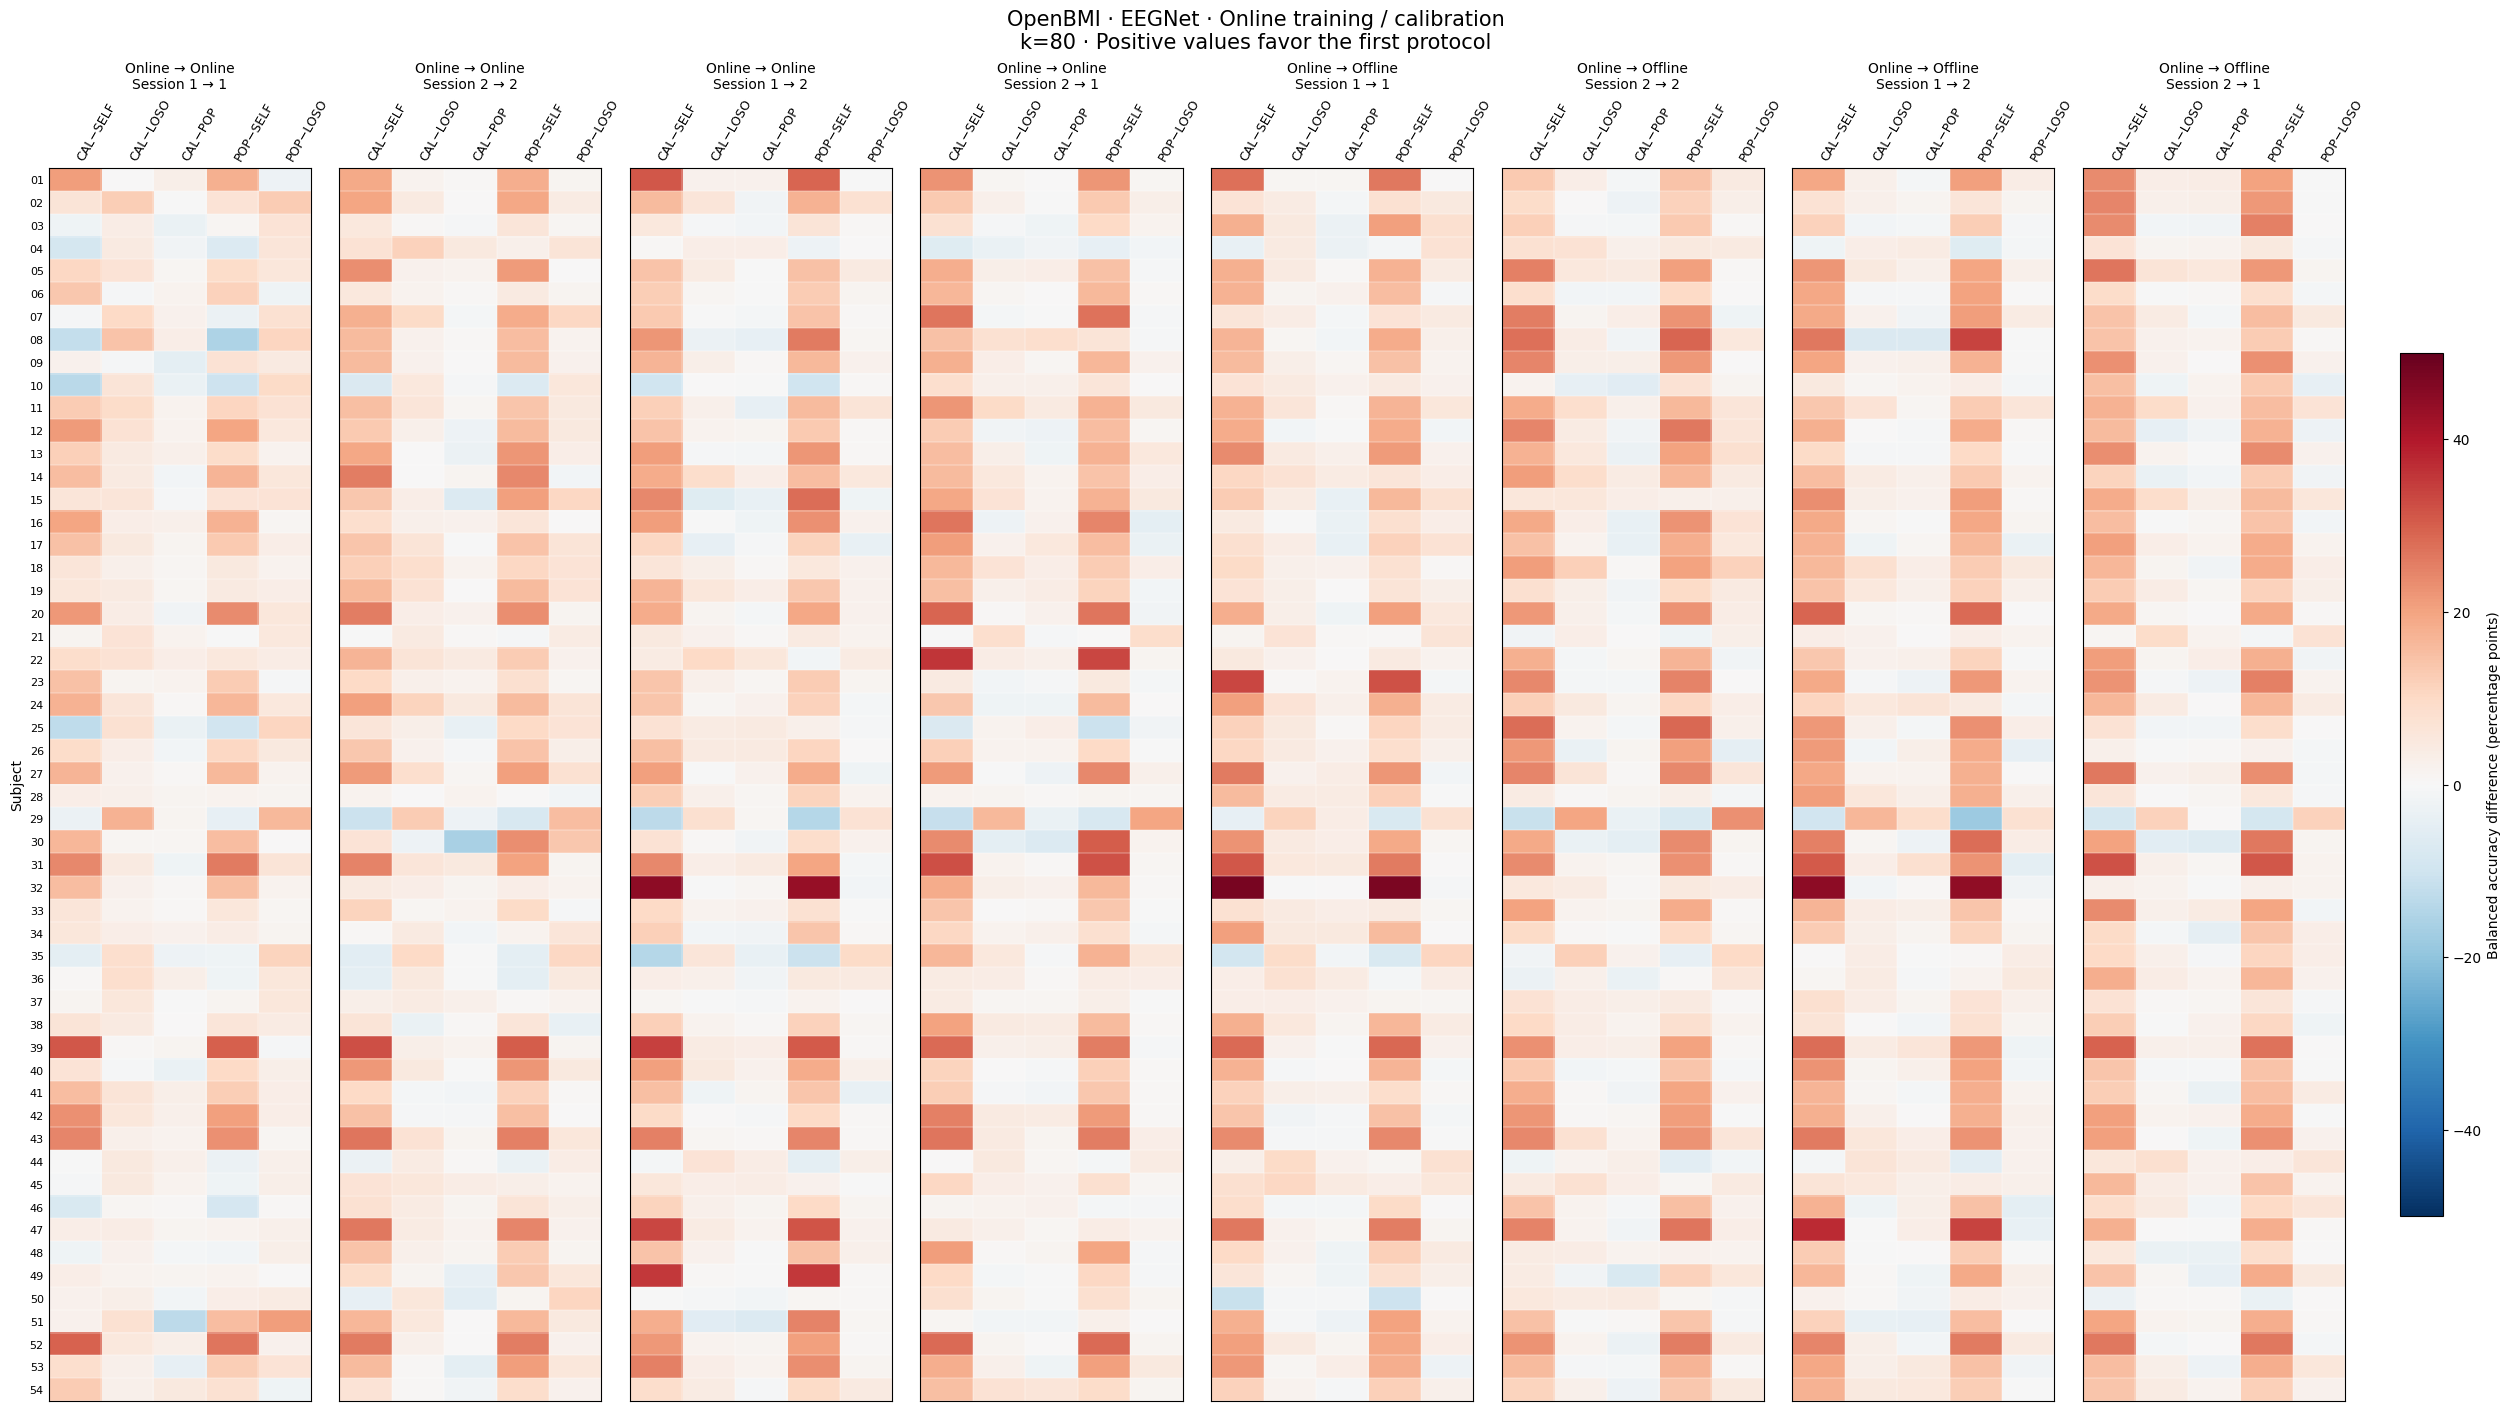

In [17]:
# ---------- 1. 计算每个被试的 protocol 收益 ----------
comparisons = [
    ("CAL", "SELF"),
    ("CAL", "LOSO"),
    ("CAL", "POP"),
    ("POP", "SELF"),
    ("POP", "LOSO"),
]
comparison_labels = [f"{a}−{b}" for a, b in comparisons]

session_pairs = [
    ("1", "1"),
    ("2", "2"),
    ("1", "2"),
    ("2", "1"),
]

subjects = list(range(1, 55))

scores = subject_scores.copy()

for col in ("train_sess", "test_ses"):
    scores[col] = (
        scores[col].astype(str)
        .str.replace(r"\.0$", "", regex=True)
    )

pair_cols = [
    "subject",
    "train_sess", "train_phases",
    "test_ses", "test_phase",
]

if scores.duplicated(pair_cols + ["protocol"]).any():
    raise ValueError("同一被试、训练—测试条件存在重复的 protocol 分数。")

paired = scores.pivot(
    index=pair_cols,
    columns="protocol",
    values="bacc",
)

required = {"SELF", "LOSO", "CAL", "POP"}
if not required.issubset(paired.columns):
    raise ValueError(
        f"缺少 protocol：{sorted(required - set(paired.columns))}"
    )

gains = pd.DataFrame(index=paired.index)

for (a, b), label in zip(comparisons, comparison_labels):
    # BACC 差值转为百分点
    gains[label] = (paired[a] - paired[b]) * 100

gains = gains.reset_index()

# ---------- 2. 构建两张图需要的矩阵 ----------
all_matrices = {}

for train_phase in ("offline", "online"):
    # 同 phase 测试在前，跨 phase 测试在后
    other_phase = "online" if train_phase == "offline" else "offline"
    panels = []

    for test_phase in (train_phase, other_phase):
        for train_ses, test_ses in session_pairs:
            selected = gains[
                (gains["train_sess"] == train_ses)
                & (gains["train_phases"] == train_phase)
                & (gains["test_ses"] == test_ses)
                & (gains["test_phase"] == test_phase)
            ]

            matrix = (
                selected.set_index("subject")
                .reindex(subjects)[comparison_labels]
            )

            if matrix.isna().any().any():
                missing = matrix.index[
                    matrix.isna().any(axis=1)
                ].tolist()
                raise ValueError(
                    f"{train_phase} → {test_phase}, "
                    f"Session {train_ses} → {test_ses} "
                    f"存在缺失分数，被试：{missing}"
                )

            panels.append({
                "matrix": matrix.to_numpy(),
                "train_ses": train_ses,
                "test_ses": test_ses,
                "test_phase": test_phase,
            })

    all_matrices[train_phase] = panels

# ---------- 3. 两张图共用对称色阶 ----------
# 例如设为 30，表示色阶固定为 -30～+30 个百分点
color_limit = None

if color_limit is None:
    max_abs = max(
        np.abs(panel["matrix"]).max()
        for panels in all_matrices.values()
        for panel in panels
    )
    color_limit = max(5, np.ceil(max_abs / 5) * 5)

norm = plt.Normalize(
    vmin=-color_limit,
    vmax=color_limit,
)
cmap = plt.get_cmap("RdBu_r")

# ---------- 4. 每张图横排八个 heatmap ----------
for train_phase, panels in all_matrices.items():
    fig, axes = plt.subplots(
        1, 8,
        figsize=(25, 14),
        sharey=True,
        layout="constrained",
    )

    for panel_id, (ax, panel) in enumerate(zip(axes, panels)):
        im = ax.imshow(
            panel["matrix"],
            cmap=cmap,
            norm=norm,
            aspect="auto",
            interpolation="nearest",
        )

        ax.set_title(
            f"{train_phase.capitalize()} → "
            f"{panel['test_phase'].capitalize()}\n"
            f"Session {panel['train_ses']} → "
            f"{panel['test_ses']}",
            fontsize=10,
        )

        ax.set_xticks(
            range(len(comparison_labels)),
            labels=comparison_labels,
            rotation=60,
            ha="left",
            fontsize=9,
        )
        ax.tick_params(
            axis="x",
            top=True,
            labeltop=True,
            bottom=False,
            labelbottom=False,
        )

        ax.set_yticks(
            range(len(subjects)),
            labels=[f"{s:02d}" for s in subjects],
        )
        ax.tick_params(
            axis="y",
            labelleft=(panel_id == 0),
            labelsize=8,
        )
        ax.tick_params(which="both", length=0)
        

        # 单元格边界
        ax.set_xticks(
            np.arange(-0.5, len(comparison_labels), 1),
            minor=True,
        )
        ax.set_yticks(
            np.arange(-0.5, len(subjects), 1),
            minor=True,
        )
        ax.grid(
            which="minor",
            color="white",
            linewidth=0.3,
        )

        if panel_id == 0:
            ax.set_ylabel("Subject")

    fig.colorbar(
        im,
        ax=axes.tolist(),
        label="Balanced accuracy difference (percentage points)",
        shrink=0.7,
        pad=0.015,
    )

    fig.suptitle(
        f"OpenBMI · EEGNet · {train_phase.capitalize()} training / calibration\n"
        f"k={k} · Positive values favor the first protocol",
        fontsize=15,
    )

    plt.show()

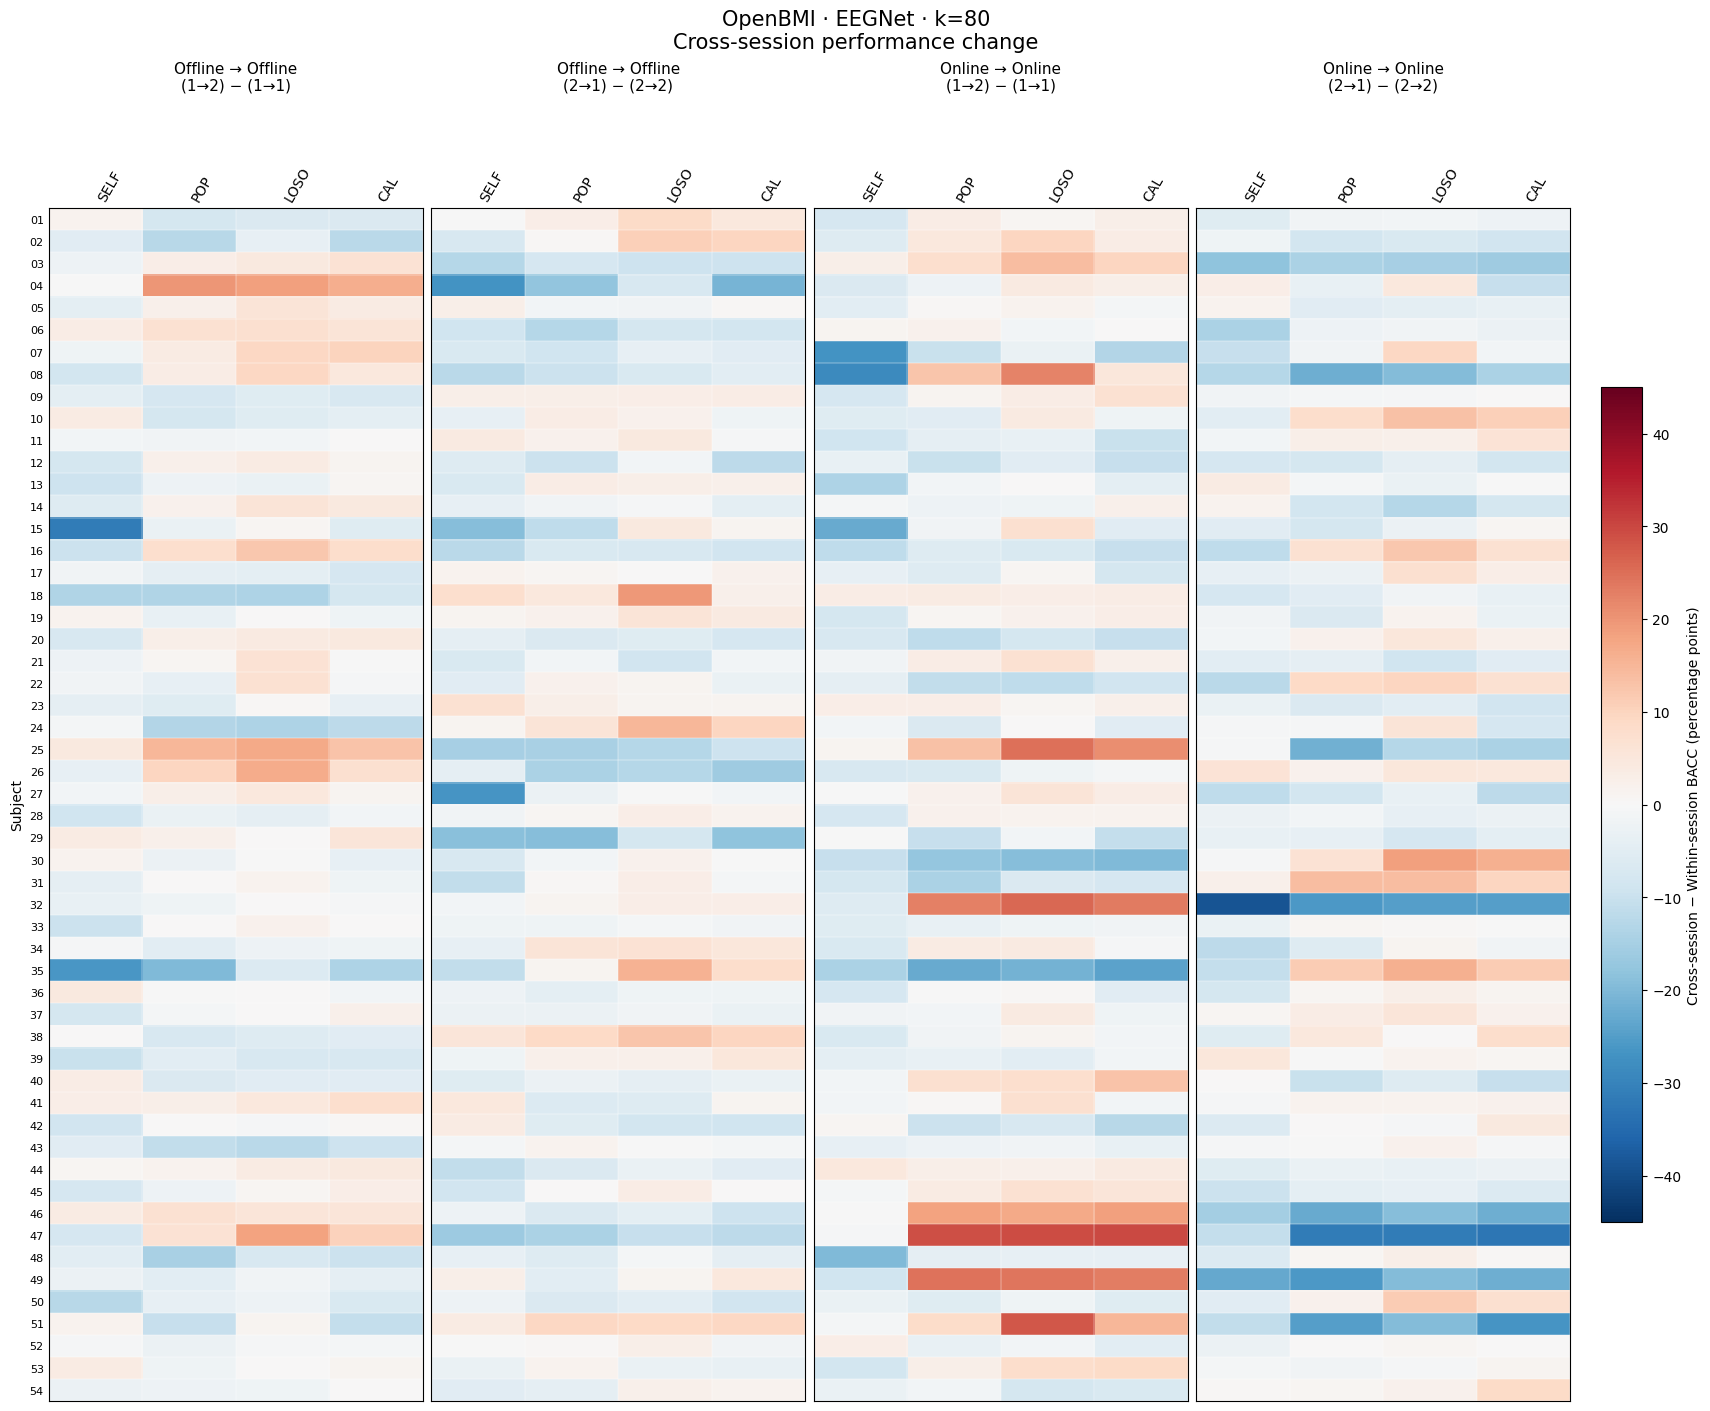

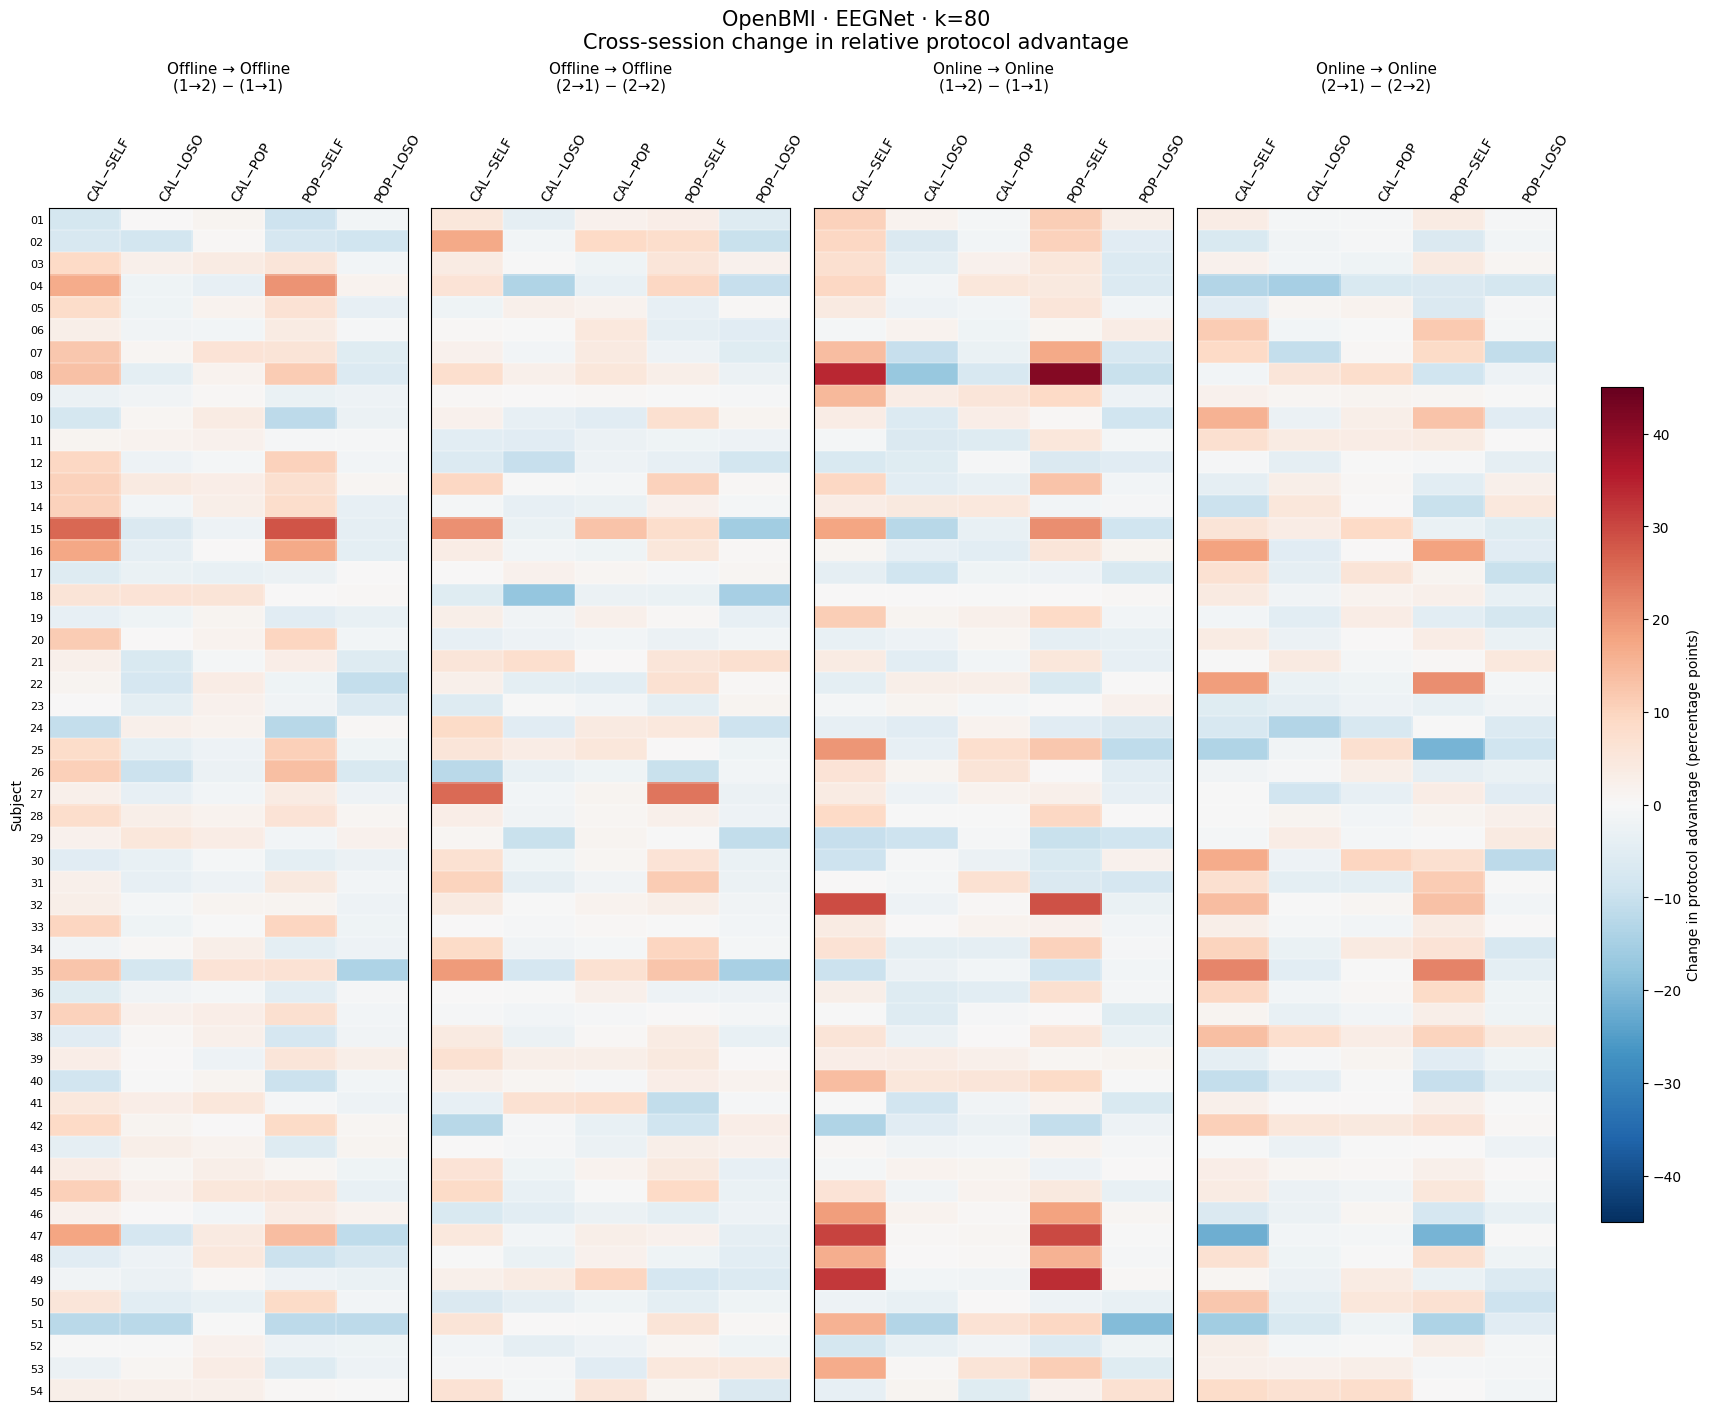

In [18]:
# ---------- 1. 准备每个被试的分数 ----------
protocol_order = ["SELF", "POP", "LOSO", "CAL"]

comparisons = [
    ("CAL", "SELF"),
    ("CAL", "LOSO"),
    ("CAL", "POP"),
    ("POP", "SELF"),
    ("POP", "LOSO"),
]
comparison_labels = [f"{a}−{b}" for a, b in comparisons]
subjects = list(range(1, 55))

session_scores = subject_scores.copy()

for col in ("train_sess", "test_ses"):
    session_scores[col] = (
        session_scores[col].astype(str)
        .str.replace(r"\.0$", "", regex=True)
    )

# ---------- 2. 跨 session − 同 session ----------
panels = []

for phase in ("offline", "online"):
    for train_ses, cross_test_ses in [("1", "2"), ("2", "1")]:
        selected = session_scores[
            (session_scores["train_sess"] == train_ses)
            & (session_scores["train_phases"] == phase)
            & (session_scores["test_phase"] == phase)
        ]

        table = selected.pivot(
            index="subject",
            columns=["protocol", "test_ses"],
            values="bacc",
        )

        delta = pd.DataFrame(index=subjects)

        for protocol in protocol_order:
            same_key = (protocol, train_ses)
            cross_key = (protocol, cross_test_ses)

            if same_key not in table.columns or cross_key not in table.columns:
                raise ValueError(
                    f"缺少条件：{protocol}, {phase}, "
                    f"训练 Session {train_ses}"
                )

            delta[protocol] = (
                table[cross_key] - table[same_key]
            ).reindex(subjects) * 100

        if delta.isna().any().any():
            missing = delta.index[
                delta.isna().any(axis=1)
            ].tolist()
            raise ValueError(
                f"{phase}, 训练 Session {train_ses}，"
                f"存在缺失分数，被试：{missing}"
            )

        # 各 protocol 的跨 session 变化之间再作差
        relative_delta = pd.DataFrame(index=subjects)

        for (a, b), label in zip(comparisons, comparison_labels):
            relative_delta[label] = delta[a] - delta[b]

        panels.append({
            "title": (
                f"{phase.capitalize()} → {phase.capitalize()}\n"
                f"({train_ses}→{cross_test_ses}) − "
                f"({train_ses}→{train_ses})"
            ),
            "delta": delta,
            "relative_delta": relative_delta,
        })

# ---------- 3. 两张图统一使用对称色阶 ----------
# 可手动改成 20、30 等；None 表示根据全部差值自动设置
color_limit = None

if color_limit is None:
    max_abs = max(
        np.abs(panel[name].to_numpy()).max()
        for panel in panels
        for name in ("delta", "relative_delta")
    )
    color_limit = max(5, np.ceil(max_abs / 5) * 5)

norm = plt.Normalize(
    vmin=-color_limit,
    vmax=color_limit,
)
cmap = plt.get_cmap("RdBu_r")

# ---------- 4. 分别画两张图 ----------
plot_settings = [
    (
        "delta",
        protocol_order,
        "Cross-session − Within-session BACC (percentage points)",
        "Cross-session performance change",
    ),
    (
        "relative_delta",
        comparison_labels,
        "Change in protocol advantage (percentage points)",
        "Cross-session change in relative protocol advantage",
    ),
]

for data_name, column_labels, colorbar_label, title in plot_settings:
    fig, axes = plt.subplots(
        1, 4,
        figsize=(17, 14),
        sharey=True,
        layout="constrained",
    )

    for panel_id, (ax, panel) in enumerate(zip(axes, panels)):
        matrix = panel[data_name][column_labels].to_numpy()

        im = ax.imshow(
            matrix,
            cmap=cmap,
            norm=norm,
            aspect="auto",
            interpolation="nearest",
        )

        ax.set_title(
            panel["title"],
            fontsize=11,
            pad=85,
        )

        ax.set_xticks(
            range(len(column_labels)),
            labels=column_labels,
            rotation=60,
            ha="left",
            fontsize=10,
        )
        ax.tick_params(
            axis="x",
            top=True,
            labeltop=True,
            bottom=False,
            labelbottom=False,
        )

        ax.set_yticks(
            range(len(subjects)),
            labels=[f"{s:02d}" for s in subjects],
        )
        ax.tick_params(
            axis="y",
            labelleft=(panel_id == 0),
            labelsize=8,
        )
        ax.tick_params(which="both", length=0)

        ax.set_xticks(
            np.arange(-0.5, len(column_labels), 1),
            minor=True,
        )
        ax.set_yticks(
            np.arange(-0.5, len(subjects), 1),
            minor=True,
        )
        ax.grid(
            which="minor",
            color="white",
            linewidth=0.3,
        )

        if panel_id == 0:
            ax.set_ylabel("Subject")

    fig.colorbar(
        im,
        ax=axes.tolist(),
        label=colorbar_label,
        shrink=0.7,
        pad=0.02,
    )

    fig.suptitle(
        f"OpenBMI · EEGNet · k={k}\n{title}",
        fontsize=15,
    )

    plt.show()